[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jalonso1979/puremacro/blob/v5.7.0/curso/notebooks/T02_D_occbin_zlb_regimes.ipynb)

# Topic 2.D: Occasionally Binding Constraints: ZLB, Irreversible Investment and Uncertainty

### Advanced Macroeconomics (MAV) — Master in Economics, ITAM
**Author**: Jorge Alonso Ortiz

> **Google Colab note**: this updated lesson uses the source at tag `v5.7.0` (puremacro 5.7.0) and models from the same checkout. The next cell installs it in Colab; locally run `python -m pip install -e ".[notebooks]"` from this repository's root and select that environment. The original `course-2026A-5.5.0` edition remains available at its tag.

> **22 October 2026 update**: sections 8–9 add irreversible investment and stochastic volatility. This updated notebook uses puremacro 5.5.0 and the frozen edition’s helpers; the original tag retains the earlier notebook. Execution checked in local Python; Colab has not been revalidated.

In [1]:
# DSGE lesson setup: local source or Colab
import os
import sys
import subprocess
from pathlib import Path

_course_requirements = ["puremacro==5.7.0"]
_course_edition = "v5.7.0"
_course_development = False

def _safe_probe(p, is_dir=None):
    """Test paths without raising in restricted notebook environments."""
    try:
        p = Path(p)
        return p.is_dir() if is_dir is True else p.is_file() if is_dir is False else p.exists()
    except (OSError, PermissionError, TypeError, ValueError):
        return False

if "google.colab" in sys.modules:
    _repo = Path("/content/puremacro-course-v5.7.0")
    if not _safe_probe(_repo, is_dir=True):
        subprocess.run(["git", "clone", "-q", "--depth", "1", "--filter=blob:none", "--sparse",
                        "--branch", "v5.7.0", "https://github.com/jalonso1979/puremacro.git", str(_repo)], check=True)
        subprocess.run(["git", "-C", str(_repo), "sparse-checkout", "set", "puremacro", "curso/notebooks"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", str(_repo)], check=True)
    os.chdir(_repo / "curso/notebooks")

# A source checkout takes precedence over an older installed course wheel.
_course_source_root = None
for _candidate in [Path.cwd(), *Path.cwd().parents]:
    if _safe_probe(_candidate / "puremacro/__init__.py", is_dir=False) and _safe_probe(_candidate / "pyproject.toml", is_dir=False):
        _course_source_root = _candidate
        if str(_candidate) not in sys.path:
            sys.path.insert(0, str(_candidate))
        break

_candidates = [Path.cwd(), Path.cwd() / "notebooks", Path.cwd() / "curso/notebooks"]
if _course_source_root is not None:
    _candidates.insert(0, _course_source_root / "curso/notebooks")
_course_helper_dir = next((_c for _c in _candidates if _safe_probe(_c / "_dsge_labs.py", is_dir=False)), None)
if _course_helper_dir is None:
    raise RuntimeError("Open this updated notebook from the matching curso/notebooks folder, including _dsge_labs.py and modelos/.")
if str(_course_helper_dir) not in sys.path:
    sys.path.insert(0, str(_course_helper_dir))

import puremacro
from puremacro import dsge
if puremacro.__version__ != "5.7.0":
    raise RuntimeError("These DSGE lessons require puremacro==5.7.0. Install the matching tag and restart the kernel.")
_course_features = ("read_mod", "solve_transition", "solve_announced_path", "solve_time_iteration", "evaluate_perturbation")
if not all(hasattr(dsge, _name) for _name in _course_features):
    raise RuntimeError("This lesson requires the updated Puremacro source (5.7.0). Install this checkout with python -m pip install -e '.[notebooks]' and restart the kernel.")
if _course_source_root is not None and not Path(puremacro.__file__).resolve().is_relative_to(_course_source_root):
    raise RuntimeError("An older puremacro was already imported. Restart this kernel to use the matching source checkout.")
print("Puremacro", puremacro.__version__, "— DSGE lessons, v5.7.0")

os.environ.setdefault("MAV_LLM_MODE", "cache")

%matplotlib inline
try:
    import _nbstyle
    _nbstyle.apply_style()
except ImportError:
    pass

import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

Puremacro 5.7.0 — DSGE lessons, v5.7.0
No event loop hook running.
No event loop hook running.


## 1. Theoretical Motivation: Why Linear Perturbation Fails at Physical Boundaries

In modern quantitative macroeconomics, dynamic stochastic general equilibrium (DSGE) models are traditionally solved using first-order Taylor expansions around the deterministic steady state (Klein 2000, Schmitt-Grohé & Uribe 2004). Linear perturbation assumes that policy functions are differentiable planes everywhere in state space.

However, actual market economies are constrained by **fundamental non-linearities and physical boundaries**:
1. **The Zero Lower Bound (ZLB) / Effective Lower Bound (ELB)**: The nominal interest rate on central bank reserves cannot plunge significantly below zero because households and financial institutions can arbitrage cash holding:
   $$i_t \ge 0 \quad \iff \quad \hat{r}_t \ge -r_{ss}$$
2. **Collateral & Borrowing Constraints (Sudden Stops)**: Emerging economy external borrowing cannot exceed a fraction of physical collateral: $d_{t+1} \le \kappa q_t k_t$ (Mendoza 2010).
3. **Downward Nominal Wage Rigidity (DNWR)**: Workers resist cuts to nominal hourly wages: $\Delta W_t \ge 0$ (Schmitt-Grohé & Uribe 2016).

When an economy suffers a massive contractionary demand shock (such as during the 2008 Great Financial Crisis or the 2020 COVID-19 shock), linear perturbation predicts that the central bank cuts the nominal policy rate to deeply negative levels (in Section 1 of this notebook, $-8.8\%$ annualized). Because nominal rates cannot fall below zero in reality, the real interest rate:
$$r_{t}^{\text{real}} = i_t - \mathbb{E}_t \pi_{t+1}$$
is driven **up** by expected deflation, sparking a severe **deflationary spiral** and amplifying the output collapse.

### The Piecewise-Linear Solution: Guerrieri & Iacoviello (2015, JME)
To solve models with occasionally binding constraints without the prohibitive curse of dimensionality of global Value Function Iteration (VFI), Guerrieri & Iacoviello (2015) introduced the **OccBin** algorithm:
- **Reference Regime ($M_1$)**: The unconstrained economy governed by an active Taylor rule.
- **Constrained Regime ($M_2$)**: The economy when the constraint binds (nominal rate clamped at the zero floor).
- **Endogenous Duration ($T^*$)**: OccBin solves a piecewise-linear approximation to the equilibrium conditions under perfect foresight via backward recursion, determining endogenously how many quarters the economy stays trapped at the lower bound before smoothly lifting off back to the reference regime.

### The 3-Equation New Keynesian Framework
In this notebook, we examine a canonical New Keynesian DSGE model:
1. **Dynamic Investment-Savings (IS) Curve**:
   $$y_t = \mathbb{E}_t y_{t+1} - \frac{1}{\sigma}\left(r_t - \mathbb{E}_t \pi_{t+1}\right) + g_t$$
2. **New Keynesian Phillips Curve (Calvo Price Stickiness)**:
   $$\pi_t = \beta \mathbb{E}_t \pi_{t+1} + \kappa y_t$$
3. **Monetary Policy Rule with Occasionally Binding Floor**:
   $$r_t = \max\left(-r_{ss}, \; \phi_\pi \pi_t + \phi_y y_t + \varepsilon_{r,t}\right)$$
4. **Exogenous Aggregate Demand / Preference Shock**:
   $$g_t = \rho_g g_{t-1} + \varepsilon_{g,t}$$

In [2]:
# ==============================================================================
# Declarative Model Ingestion & OccBin Constraint Setup
# ==============================================================================
from puremacro.dsge import load_mod, OccBinConstraint, solve_occbin, build_dynare, make_state_space_from_varobs
from puremacro.dsge.occbin import solve_multiconstraint_occbin, piecewise_kalman_filter
from puremacro.state_space import kalman_filter

# Resolve model paths across local repository and Colab environments
from _datos import ruta_modelo

# Resolve model paths across local repository, sandbox, and Colab environments
ref_mod_path = ruta_modelo("nk_zlb_ref.mod")
cons_mod_path = ruta_modelo("nk_zlb_cons.mod")

# Load canonical Dynare specifications natively via puremacro
ref_model = load_mod(ref_mod_path)
# The constrained regime pegs r = -r_ss, dropping the Taylor rule, so on its own it
# fails Blanchard-Kahn by construction: with the policy rate fixed there is nothing
# left to anchor inflation. That is expected in Guerrieri-Iacoviello -- the ZLB regime
# is only well defined as a segment of the piecewise path, whose terminal condition
# comes from the reference regime. strict=False returns its structural matrices
# instead of raising; solve_occbin needs exactly those.
cons_model = load_mod(cons_mod_path, strict=False)

print(f"Reference Model loaded: {ref_mod_path.name}")
print(f"  States  : {ref_model.states}")
print(f"  Controls: {ref_model.controls}")
print(f"  Shocks  : {ref_model.shocks}")

# Define the occasionally binding constraint:
# When notional nominal rate r falls below -r_ss (-1.0% quarterly = 0% level), the floor binds
r_ss = float(getattr(ref_model, "_params", {}).get("r_ss", 0.01))
constraint = OccBinConstraint(variable="r", threshold=-r_ss, operator="<")

print(f"\nOccBin Constraint declared: {constraint}")
print(f"Steady-State Quarterly Policy Rate: {r_ss:.4f} ({r_ss * 400:.2f}% annualized)")
print(f"ZLB Floor on Deviation: r >= {-r_ss:.4f}")


Reference Model loaded: nk_zlb_ref.mod
  States  : ('g',)
  Controls: ('y', 'pi', 'r')
  Shocks  : ('eps_r', 'eps_g')

OccBin Constraint declared: OccBinConstraint(r < -0.01)
Steady-State Quarterly Policy Rate: 0.0100 (4.00% annualized)
ZLB Floor on Deviation: r >= -0.0100


## 2. Section 1: The Asymmetry Arena — Breaking Linear Symmetry at the ZLB

In a linear world, macroeconomic shocks exhibit perfect mirror symmetry:
$$\text{IRF}(+\varepsilon) = -\text{IRF}(-\varepsilon)$$
An aggregate demand expansion of $+2.5\%$ and an aggregate demand contraction of $-2.5\%$ must generate output responses of identical magnitude and opposite sign.

**In the real world, this symmetry fails completely because of the Zero Lower Bound**:
- When a positive demand shock hits ($\varepsilon_g = +2.5\%$), the central bank increases nominal interest rates along the Taylor rule ($i_t \uparrow$), leaning against inflation and smoothly moderating the boom.
- When a negative demand shock hits ($\varepsilon_g = -2.5\%$), the central bank cuts rates until it hits the zero floor. Beyond that point, monetary policy is paralyzed. Expected deflation increases the real interest rate, depressing consumption and creating an asymmetric output crash.

In addition, `solve_occbin` traces the exact binary regime transition sequence $R_t \in \{0, 1\}$ (`res_neg.regimes`), recording the endogenous spell where the economy binds at the ZLB ($R_t=1$) before returning smoothly to the unconstrained reference regime ($R_t=0$), strictly respecting the zero lower bound ($r_t \ge -r_{ss}$).

Below, we solve both the linear counterfactual and the OccBin piecewise-linear solution under both shocks.

MACROECONOMIC SHOCK ASYMMETRY SCORECARD (T=1 IMPACT)
Positive Demand (+2.5%) : Output Gap =  +3.78%, Policy Rate =  16.79% ann (ZLB periods: 0)
Linear Negative (-2.5%) : Output Gap =  -3.78%, Policy Rate =  -8.79% ann (Unconstrained shadow)
OccBin Negative (-2.5%) : Output Gap = -10.91%, Policy Rate =   0.00% ann (ZLB periods: 6)
----------------------------------------------------------------------------
Asymmetry Ratio (|y_neg| / y_pos) : 2.89x (Linear model is identically 1.00x)
ZLB Output Gap Loss vs Linear   : 7.13 percentage points deeper recession

OCCBIN BINARY REGIME TRANSITION DYNAMICS
Regime History Sequence (0=Reference, 1=Binding ZLB):
  [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Total Quarters at ZLB: 6 quarters
Terminal Regime: 0 (smooth liftoff to reference regime)
Minimum Policy Rate Deviation: -0.010000 (ZLB floor: -0.010000)


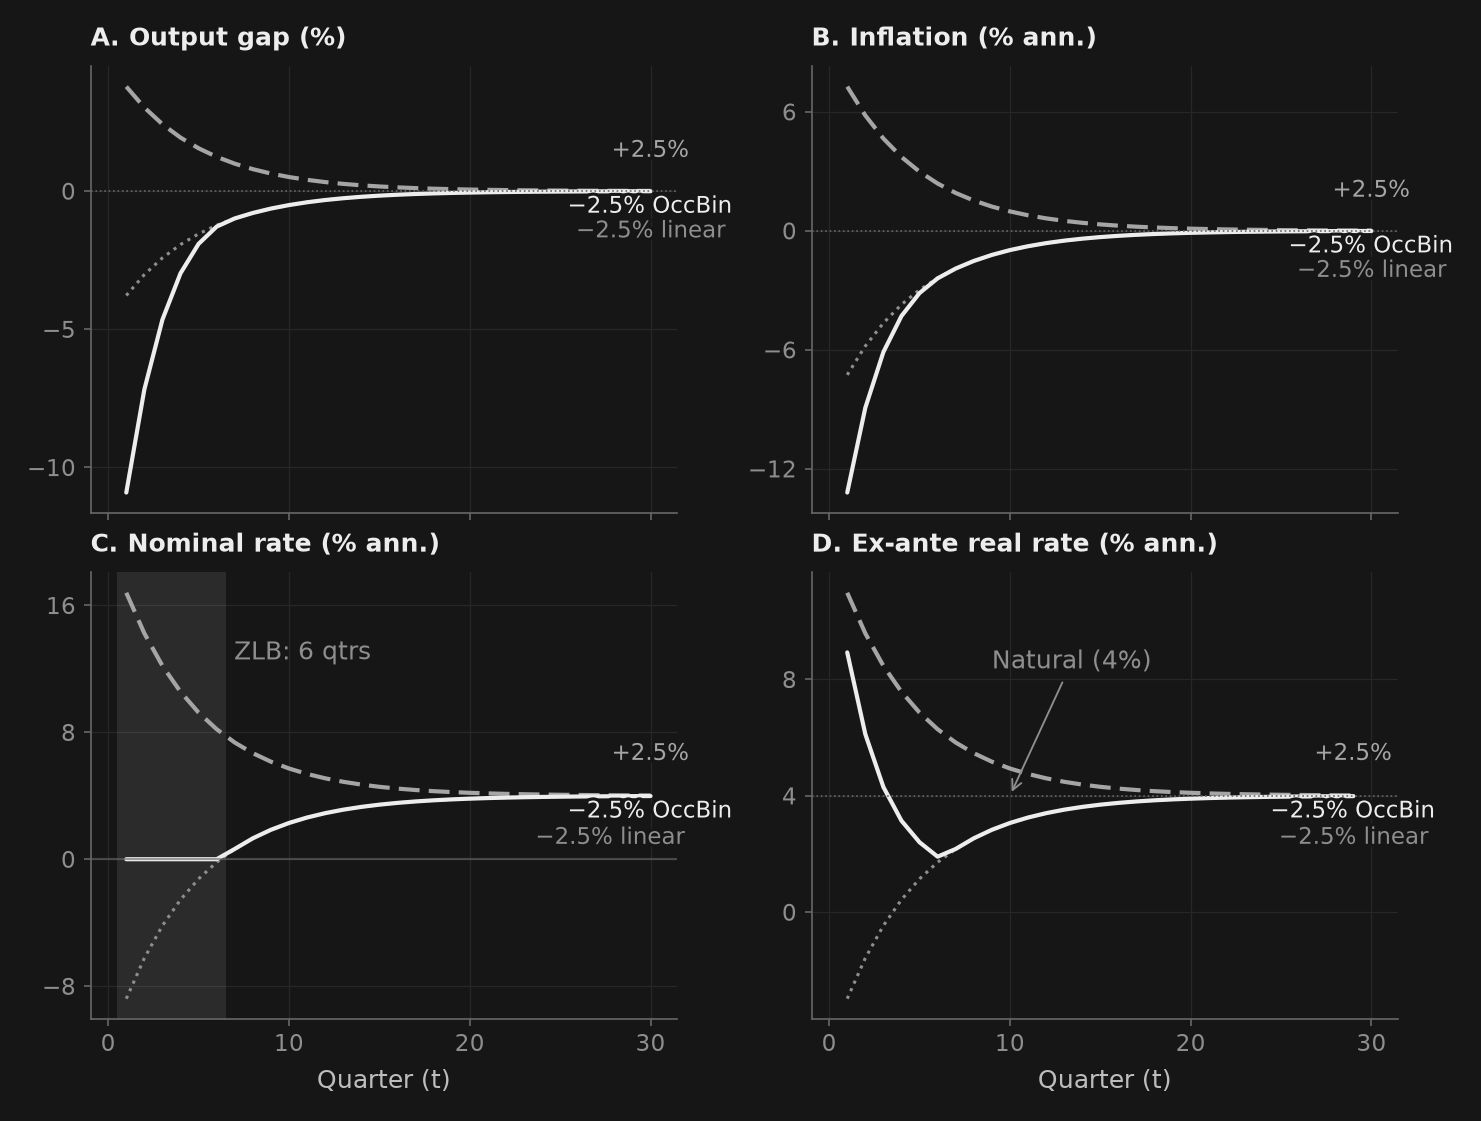

In [3]:
# ==============================================================================
# Simulation 1: The Shock Asymmetry Laboratory (+2.5% vs -2.5%)
# ==============================================================================
horizon = 30
shock_size = 0.025  # 2.5% demand shock

# 1. OccBin Piecewise-Linear Solutions
shock_pos = np.array([0.0, shock_size])
shock_neg = np.array([0.0, -shock_size])

res_pos = solve_occbin(ref_model, cons_model, constraint, shock_sequence=shock_pos, horizon=horizon)
res_neg = solve_occbin(ref_model, cons_model, constraint, shock_sequence=shock_neg, horizon=horizon)

# 2. Pure Linear Counterfactual (Taylor rule allowed to cut into negative rates)
dr = ref_model.decision_rules()
P_0 = np.zeros((len(ref_model.variables), len(ref_model.variables)))
for s in ref_model.states:
    idx_s = list(ref_model.variables).index(s)
    P_0[:, idx_s] = dr.ghx[s].values

lin_neg = np.zeros((horizon, len(ref_model.variables)))
lin_neg[0] = dr.ghu.values @ shock_neg
for t in range(1, horizon):
    lin_neg[t] = P_0 @ lin_neg[t - 1]

lin_df = pd.DataFrame(lin_neg, columns=ref_model.variables)

# Quantitative Scorecard
y_pos_0 = res_pos["y"].iloc[0] * 100
r_pos_0 = (r_ss + res_pos["r"].iloc[0]) * 400
y_neg_0 = res_neg["y"].iloc[0] * 100
r_neg_0 = (r_ss + res_neg["r"].iloc[0]) * 400
y_lin_0 = lin_df["y"].iloc[0] * 100
r_lin_0 = (r_ss + lin_df["r"].iloc[0]) * 400

asymmetry_ratio = abs(y_neg_0) / y_pos_0
zlb_penalty = abs(y_neg_0) - abs(y_lin_0)

print("=" * 76)
print("MACROECONOMIC SHOCK ASYMMETRY SCORECARD (T=1 IMPACT)")
print("=" * 76)
print(f"Positive Demand (+2.5%) : Output Gap = {y_pos_0:+6.2f}%, Policy Rate = {r_pos_0:6.2f}% ann (ZLB periods: {res_pos.binding_periods})")
print(f"Linear Negative (-2.5%) : Output Gap = {y_lin_0:+6.2f}%, Policy Rate = {r_lin_0:6.2f}% ann (Unconstrained shadow)")
print(f"OccBin Negative (-2.5%) : Output Gap = {y_neg_0:+6.2f}%, Policy Rate = {r_neg_0:6.2f}% ann (ZLB periods: {res_neg.binding_periods})")
print("-" * 76)
print(f"Asymmetry Ratio (|y_neg| / y_pos) : {asymmetry_ratio:.2f}x (Linear model is identically 1.00x)")
print(f"ZLB Output Gap Loss vs Linear   : {zlb_penalty:.2f} percentage points deeper recession")
print("=" * 76)

# Binary Regime Sequence and ZLB Floor Verification
print("\n" + "=" * 76)
print("OCCBIN BINARY REGIME TRANSITION DYNAMICS")
print("=" * 76)
print(f"Regime History Sequence (0=Reference, 1=Binding ZLB):")
print(f"  {res_neg.regimes}")
print(f"Total Quarters at ZLB: {res_neg.binding_periods} quarters")
print(f"Terminal Regime: {res_neg.regimes[-1]} (smooth liftoff to reference regime)")
print(f"Minimum Policy Rate Deviation: {res_neg['r'].min():.6f} (ZLB floor: {-r_ss:.6f})")
print("=" * 76)

assert res_neg.converged is True, "OccBin regime iterations must converge."
assert res_neg.regimes[-1] == 0, "Terminal regime must return to unconstrained reference regime."
assert np.all(res_neg["r"].values >= -r_ss - 1e-10), "ZLB floor violation: r_t fell below -r_ss!"

# Visualization
from matplotlib.ticker import MaxNLocator

time = np.arange(1, horizon + 1)

# The slide harness sets rcParams["figure.figsize"] to the slot BEFORE the cell draws.
# Inheriting it is what makes one cell serve both readings: a figure laid out at
# notebook size and shrunk afterwards keeps its annotations where the old axes were.
# In the notebook the house 2x2 still applies.
_ranura = tuple(plt.rcParams["figure.figsize"]) if os.environ.get("MAV_NB_PERFIL") == "lamina" else None
fig, axes = _nbstyle.figura(2, 2, sharex=True, figsize=_ranura)

# At slot width a column is ~2.6 in: seven ticks per axis pile on top of each other.
for _ax in axes.flat:
    _ax.xaxis.set_major_locator(MaxNLocator(4, integer=True))
    _ax.yaxis.set_major_locator(MaxNLocator(4))

# The linear counterfactual stays thinner than the two OccBin paths in both profiles.
lw_lin = plt.rcParams["lines.linewidth"] * 0.75

# The units ride in each panel's title: at a 2.6-in column a rotated axis label is
# taller than the panel itself and gets clipped.
ETIQ = ("+2.5%", "−2.5% linear", "−2.5% OccBin")

# Panel A: Output Gap
ax = axes[0, 0]
ax.plot(time, res_pos["y"] * 100, label=ETIQ[0], **_nbstyle.S2)
ax.plot(time, lin_df["y"] * 100, label=ETIQ[1], color=_nbstyle.NOTA, linestyle=":", linewidth=lw_lin)
ax.plot(time, res_neg["y"] * 100, label=ETIQ[2], **_nbstyle.S1)
ax.axhline(0, color=_nbstyle.SPINE, linestyle=":", linewidth=0.8)
ax.set_title("A. Output gap (%)")
_nbstyle.etiquetar(ax)

# Panel B: Inflation (Annualized)
ax = axes[0, 1]
ax.plot(time, res_pos["pi"] * 400, label=ETIQ[0], **_nbstyle.S2)
ax.plot(time, lin_df["pi"] * 400, label=ETIQ[1], color=_nbstyle.NOTA, linestyle=":", linewidth=lw_lin)
ax.plot(time, res_neg["pi"] * 400, label=ETIQ[2], **_nbstyle.S1)
ax.axhline(0, color=_nbstyle.SPINE, linestyle=":", linewidth=0.8)
ax.set_title("B. Inflation (% ann.)")
_nbstyle.etiquetar(ax)

# Panel C: Nominal Policy Rate (Annualized Level)
ax = axes[1, 0]
ax.plot(time, (r_ss + res_pos["r"]) * 400, label=ETIQ[0], **_nbstyle.S2)
ax.plot(time, (r_ss + lin_df["r"]) * 400, label=ETIQ[1], color=_nbstyle.NOTA, linestyle=":", linewidth=lw_lin)
ax.plot(time, (r_ss + res_neg["r"]) * 400, label=ETIQ[2], **_nbstyle.S1)
ax.axhline(0, color=_nbstyle.SPINE, linestyle="-", linewidth=1.0, alpha=0.6)
ax.axvspan(0.5, res_neg.binding_periods + 0.5, color=_nbstyle.RECESION, lw=0)
ax.annotate(f"ZLB: {res_neg.binding_periods} qtrs", xy=(res_neg.binding_periods + 0.5, 13.0),
            xytext=(4, 0), textcoords="offset points", ha="left", va="center", color=_nbstyle.NOTA)
ax.set_xlabel("Quarter (t)")
ax.set_title("C. Nominal rate (% ann.)")
_nbstyle.etiquetar(ax)

# Panel D: Real Interest Rate Level
ax = axes[1, 1]
r_real_pos = (res_pos["r"].iloc[:-1].values - res_pos["pi"].iloc[1:].values + r_ss) * 400
r_real_lin = (lin_df["r"].iloc[:-1].values - lin_df["pi"].iloc[1:].values + r_ss) * 400
r_real_neg = (res_neg["r"].iloc[:-1].values - res_neg["pi"].iloc[1:].values + r_ss) * 400

ax.plot(time[:-1], r_real_pos, label=ETIQ[0], **_nbstyle.S2)
ax.plot(time[:-1], r_real_lin, label=ETIQ[1], color=_nbstyle.NOTA, linestyle=":", linewidth=lw_lin)
ax.plot(time[:-1], r_real_neg, label=ETIQ[2], **_nbstyle.S1)
ax.axhline(r_ss * 400, color=_nbstyle.SPINE, linestyle=":", linewidth=0.8)
# The natural-rate line is named from the empty space above: next to its own trace the three paths cover it
ax.annotate(f"Natural ({r_ss * 400:.0f}%)", xy=(10.0, r_ss * 400), xytext=(9.0, 8.6),
            ha="left", va="center", color=_nbstyle.NOTA, arrowprops=_nbstyle.FLECHA)
ax.set_xlabel("Quarter (t)")
ax.set_title("D. Ex-ante real rate (% ann.)")
_nbstyle.etiquetar(ax)

plt.show()


## 3. Section 2: The Keynesian Multiplier Supercharge at the Zero Lower Bound

A foundational result in macroeconomic policy analysis (Christiano, Eichenbaum & Rebelo 2011, *JPE*; Eggertsson 2011; Woodford 2011) concerns the **state-dependence of the government spending multiplier**:

$$\text{Multiplier} = \frac{\partial Y_t}{\partial G_t}$$

### The Transmission Channel: Crowding Out vs. Crowding In
1. **Normal Times (Active Taylor Rule)**:
   - When the government increases spending $G_t \uparrow$, aggregate demand and inflation rise.
   - Because the Taylor rule satisfies the Taylor Principle ($\phi_\pi = 1.5 > 1$), the central bank responds aggressively by hiking the nominal policy rate $i_t$ by more than the rise in inflation.
   - The **real interest rate rises** ($r_t^{\text{real}} \uparrow$), which induces households to postpone consumption and firms to reduce investment. Private spending is **crowded out**, keeping the output multiplier modest (in the literature, $\sim 0.7 - 0.9$; in this model, $1.5$).

2. **Liquidity Trap (Zero Lower Bound Floor)**:
   - At the ZLB, the nominal policy rate is pinned at zero ($i_t = 0$).
   - When fiscal stimulus $G_t \uparrow$ stimulates activity, it raises future expected inflation ($\mathbb{E}_t \pi_{t+1} \uparrow$).
   - Because the nominal rate cannot move, the **real interest rate drops directly**:
     $$\Delta r_{t}^{\text{real}} = 0 - \Delta \mathbb{E}_t \pi_{t+1} < 0$$
   - A lower real interest rate during a recession stimulates consumption and investment (**crowding in**), causing the fiscal multiplier to **supercharge well above 2.0** (in this model, $6.8$)!

FISCAL SPENDING MULTIPLIER COMPARISON
Normal Times Fiscal Multiplier (Taylor rule active) :  1.512
ZLB Liquidity Trap Multiplier (Nominal rate pegged)  :  6.838
Fiscal Multiplier Amplification Ratio                 :   4.52x


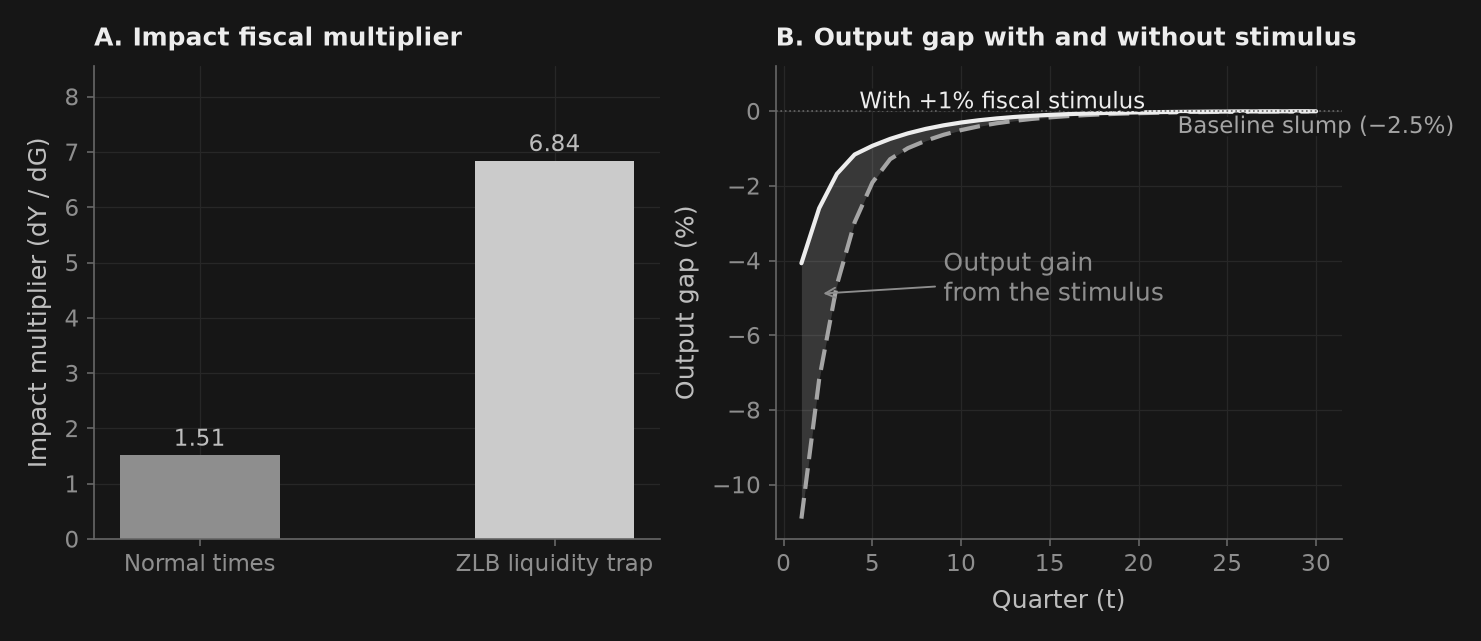

In [4]:
# ==============================================================================
# Simulation 2: Fiscal Multiplier Comparison (Normal Times vs ZLB)
# ==============================================================================
stimulus_size = 0.01  # +1% of GDP fiscal expansion

# 1. Normal Times Multiplier (Zero Baseline vs +1% Stimulus)
res_normal_base = solve_occbin(ref_model, cons_model, constraint, shock_sequence=np.array([0.0, 0.0]), horizon=horizon)
res_normal_stim = solve_occbin(ref_model, cons_model, constraint, shock_sequence=np.array([0.0, stimulus_size]), horizon=horizon)
multiplier_normal = (res_normal_stim["y"].iloc[0] - res_normal_base["y"].iloc[0]) / stimulus_size

# 2. ZLB Liquidity Trap Multiplier (-2.5% Recession vs -1.5% Net with Stimulus)
res_zlb_base = res_neg  # -2.5% demand shock
shock_zlb_stim = np.array([0.0, -shock_size + stimulus_size])  # -1.5% net shock
res_zlb_stim = solve_occbin(ref_model, cons_model, constraint, shock_sequence=shock_zlb_stim, horizon=horizon)
multiplier_zlb = (res_zlb_stim["y"].iloc[0] - res_zlb_base["y"].iloc[0]) / stimulus_size

amplification = multiplier_zlb / multiplier_normal

print("=" * 76)
print("FISCAL SPENDING MULTIPLIER COMPARISON")
print("=" * 76)
print(f"Normal Times Fiscal Multiplier (Taylor rule active) : {multiplier_normal:6.3f}")
print(f"ZLB Liquidity Trap Multiplier (Nominal rate pegged)  : {multiplier_zlb:6.3f}")
print(f"Fiscal Multiplier Amplification Ratio                 : {amplification:6.2f}x")
print("=" * 76)

# Visualization
fig, (ax1, ax2) = _nbstyle.figura(1, 2)

# Bar chart of impact multiplier
ax1.bar(["Normal times", "ZLB liquidity trap"], [multiplier_normal, multiplier_zlb], color=[_nbstyle.BARRA_COLORES[1], _nbstyle.BARRA_COLORES[0]], width=0.45)
ax1.set_ylabel("Impact multiplier (dY / dG)")
ax1.set_title("A. Impact fiscal multiplier")
ax1.set_ylim(0, max(multiplier_normal, multiplier_zlb) * 1.25)
_nbstyle.etiquetar_barras(ax1, fmt="{:.2f}")

# Dynamic trajectories under stimulus vs baseline in liquidity trap
ax2.plot(time, res_zlb_base["y"] * 100, label="Baseline slump (−2.5%)", **_nbstyle.S2)
ax2.plot(time, res_zlb_stim["y"] * 100, label="With +1% fiscal stimulus", **_nbstyle.S1)
ax2.fill_between(time, res_zlb_base["y"] * 100, res_zlb_stim["y"] * 100, color=_nbstyle.BANDA, lw=0)
ax2.axhline(0, color=_nbstyle.SPINE, linestyle=":", linewidth=0.8)
ax2.set_ylim(top=1.2)
ax2.annotate("Output gain\nfrom the stimulus", xy=(time[1], (res_zlb_base["y"].iloc[1] + res_zlb_stim["y"].iloc[1]) * 50),
             xytext=(9.0, -4.5), ha="left", va="center", color=_nbstyle.NOTA, arrowprops=_nbstyle.FLECHA)
ax2.set_xlabel("Quarter (t)")
ax2.set_ylabel("Output gap (%)")
ax2.set_title("B. Output gap with and without stimulus")
_nbstyle.etiquetar(ax2)

plt.show()


## 4. Section 3: Endogenous ZLB Duration $T^*$ & The Deflationary Spiral Monotonicity

Unlike simple ad-hoc pegging models, the Guerrieri & Iacoviello (2015) algorithm does not assume how long the economy remains trapped at zero. The duration $T^*$ is an **endogenous rational expectations equilibrium outcome**:

$$T^* = \min \left\{ t \ge 1 \;\Big|\; i_t^{\text{shadow}} \ge -r_{ss} \right\}$$

### The Deflationary Spiral Acceleration
As the adverse demand shock becomes incrementally larger:
1. The duration $T^*$ steps up discretely (from 0 to 2, 3, 5, 6 and 7 quarters).
2. Each additional quarter spent at the ZLB compounds expected deflation in the New Keynesian Phillips Curve:
   $$\pi_t = \sum_{j=0}^{T^*} \beta^j \kappa y_{t+j} + \beta^{T^*+1} \mathbb{E}_t \pi_{t+T^*+1}$$
3. Because higher expected future deflation raises current real interest rates, the initial output collapse accelerates **non-linearly** beyond a critical shock threshold.

OCCBIN DURATION & DEFLATIONARY SPIRAL MONOTONICITY SWEEP
 Shock (%)  ZLB Duration T* (qtrs)  Output Trough (%)  Inflation Trough (% ann.)  Converged  Iterations
   -0.5               0                 -0.755814              -1.453488            True         1     
   -1.0               2                 -1.816279              -3.038047            True         2     
   -1.5               3                 -4.072749              -5.483027            True         2     
   -2.0               5                 -7.179398              -8.927097            True         2     
   -2.5               6                -10.911173             -13.202295            True         2     
   -3.0               7                -15.127353             -18.148273            True         2     
   -3.5               7                -19.964928             -23.975065            True         2     


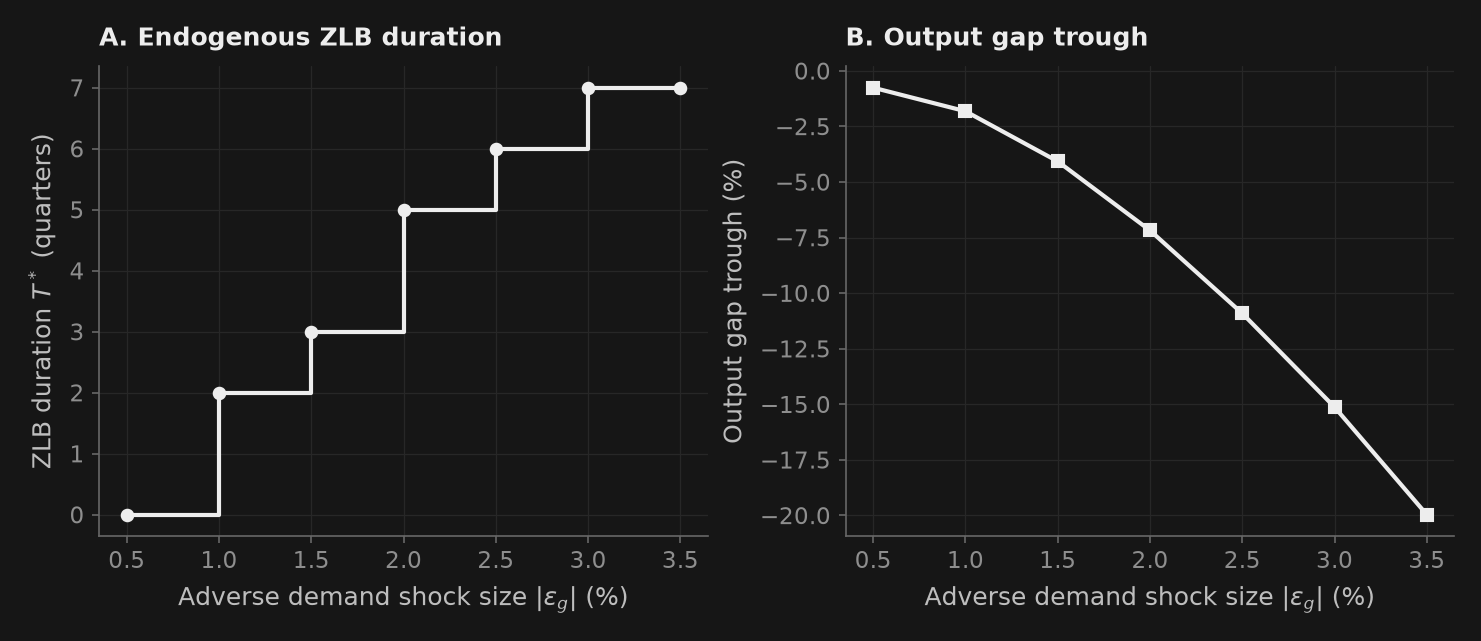

In [5]:
# ==============================================================================
# Simulation 3: Parametric Sweep over Shock Severity & ZLB Duration
# ==============================================================================
shock_grid = np.linspace(-0.005, -0.035, 7)  # -0.5% to -3.5%
sweep_results = []

for s in shock_grid:
    res_s = solve_occbin(ref_model, cons_model, constraint, shock_sequence=np.array([0.0, s]), horizon=horizon)
    y_min = res_s["y"].min() * 100
    pi_min = res_s["pi"].min() * 400
    sweep_results.append({
        "Shock (%)": s * 100,
        "ZLB Duration T* (qtrs)": res_s.binding_periods,
        "Output Trough (%)": y_min,
        "Inflation Trough (% ann.)": pi_min,
        "Converged": res_s.converged,
        "Iterations": res_s.iterations,
    })

sweep_df = pd.DataFrame(sweep_results)

print("=" * 76)
print("OCCBIN DURATION & DEFLATIONARY SPIRAL MONOTONICITY SWEEP")
print("=" * 76)
print(sweep_df.to_string(index=False, justify="center"))
print("=" * 76)

# Visualization of non-linear duration and output acceleration
fig, (ax1, ax2) = _nbstyle.figura(1, 2)

ax1.step(abs(sweep_df["Shock (%)"]), sweep_df["ZLB Duration T* (qtrs)"], where="post", marker="o", **_nbstyle.S1)
ax1.set_xlabel("Adverse demand shock size $|\\varepsilon_g|$ (%)")
ax1.set_ylabel("ZLB duration $T^*$ (quarters)")
ax1.set_title("A. Endogenous ZLB duration")

ax2.plot(abs(sweep_df["Shock (%)"]), sweep_df["Output Trough (%)"], marker="s", **_nbstyle.S1)
ax2.set_xlabel("Adverse demand shock size $|\\varepsilon_g|$ (%)")
ax2.set_ylabel("Output gap trough (%)")
ax2.set_title("B. Output gap trough")

plt.show()


## 5. Section 4: Forward Guidance & "Lower-for-Longer" Monetary Commitments

When the nominal policy rate is trapped at zero, standard open-market operations lose direct interest-rate traction. In response, modern central banks (such as the Federal Reserve, the European Central Bank, and the Bank of Japan) turn to **Forward Guidance** (Eggertsson & Woodford 2003, Del Negro, Giannoni & Patterson 2015):

> *"The central bank commits to keeping the policy rate at zero even after the natural rate of interest has recovered and the economic fundamentals would otherwise call for a rate hike."*

### The Economic Mechanism of Forward Guidance
- Under rational expectations, promising to keep nominal rates at zero in future periods $T^*+1$ creates **expected future inflation** ($\mathbb{E}_t \pi_{T^*+1} > 0$) and an expected future economic boom ($\mathbb{E}_t y_{T^*+1} > 0$).
- By the backward-looking discounting of the Euler equation and the Phillips curve, these future expectations immediately **lower real interest rates today**:
  $$y_t = \mathbb{E}_t y_{T^*+2} - \frac{1}{\sigma} \sum_{j=0}^{T^*+1} \left(r_{t+j} - \mathbb{E}_t \pi_{t+j+1}\right)$$
- Therefore, a credible promise to hold rates "lower for longer" stimulates output and halts deflation in period $t=1$ without moving the current nominal rate by a single basis point!

Baseline ZLB spell: 6 quarters -> rate held at zero through t=7
ZLB spell under the commitment: 7 quarters
FORWARD GUIDANCE POLICY EXPERIMENT
Standard Liftoff Impact Output Gap (t=1)         : -10.91%
With Forward Guidance Liftoff Commitment (t=1)  : -10.29%
Initial Output Protection from Forward Guidance :  +0.62 percentage points


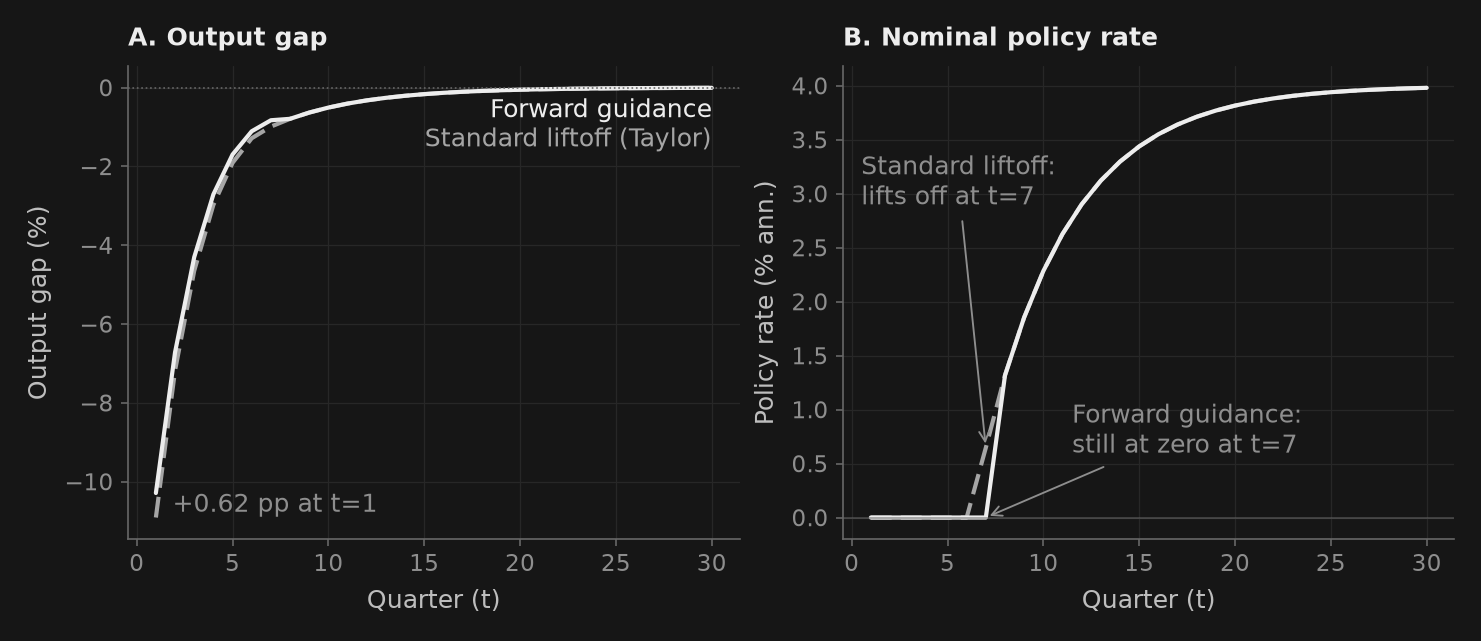

In [6]:
# ==============================================================================
# Simulation 4: Forward Guidance Commitment vs Standard Taylor Rule Liftoff
# ==============================================================================
# Model standard liftoff: the ZLB spell of Section 1's -2.5% shock, then standard Taylor rule
res_standard = res_neg

# Model Forward Guidance: the commitment has to bite AFTER the rule would have lifted off.
# While the constraint binds the policy rate is pegged at -r_ss, so an easing shock placed
# inside the binding window is absorbed exactly by the peg and changes nothing -- which is
# the whole content of "the central bank has run out of room". "Lower for longer" means
# committing to keep the rate at zero through the first quarter the Taylor rule would have
# started hiking, which extends the ZLB spell by a quarter and works backwards through the
# Euler equation onto output today. The commitment has to cover the whole extended spell,
# not just the extra quarter: the zero rate promised at liftoff raises inflation the quarter
# before, and a rule left free there lifts off for one quarter and then cuts back to zero --
# two spells instead of one longer one. Wherever the floor binds the peg absorbs the easing,
# so its size only has to keep the notional rate below the floor.
liftoff_idx = int(res_standard.binding_periods)   # first quarter the Taylor rule would lift off

fg_shocks = np.zeros((horizon, 2))
fg_shocks[0, 1] = -0.025                  # Adverse demand shock at t=1
fg_shocks[:liftoff_idx + 1, 0] = -0.005   # Commitment to hold the rate at zero through liftoff, announced at t=1

res_fg = solve_occbin(ref_model, cons_model, constraint, shock_sequence=fg_shocks, horizon=horizon)

# Length of the ZLB spell that opens at t=1 (index of the first slack quarter).
# `binding_periods` counts every binding quarter, so it is the spell length only if there is no gap.
spell_standard = int(np.argmin(res_standard.regimes))
spell_fg = int(np.argmin(res_fg.regimes))

print(f"Baseline ZLB spell: {spell_standard} quarters -> rate held at zero through t={liftoff_idx + 1}")
print(f"ZLB spell under the commitment: {spell_fg} quarters")

print("=" * 76)
print("FORWARD GUIDANCE POLICY EXPERIMENT")
print("=" * 76)
print(f"Standard Liftoff Impact Output Gap (t=1)         : {res_standard['y'].iloc[0] * 100:6.2f}%")
print(f"With Forward Guidance Liftoff Commitment (t=1)  : {res_fg['y'].iloc[0] * 100:6.2f}%")
print(f"Initial Output Protection from Forward Guidance : {(res_fg['y'].iloc[0] - res_standard['y'].iloc[0]) * 100:+6.2f} percentage points")
print("=" * 76)

assert res_fg.converged is True, "The forward-guidance path must be a verified OccBin solution."
# A single spell from t=1 in each path: no quarter binds after the first slack one.
assert res_standard.binding_periods == spell_standard, f"Baseline has a second ZLB spell: {res_standard.regimes}"
assert res_fg.binding_periods == spell_fg, (
    f"Lower-for-longer must hold the rate at the floor without a gap: {res_fg.regimes}"
)
assert spell_fg == spell_standard + 1, (
    "Lower-for-longer must extend the ZLB spell by exactly one quarter beyond the Taylor-rule liftoff."
)
assert res_fg["y"].iloc[0] > res_standard["y"].iloc[0], (
    "A credible commitment to ease at liftoff must raise output on impact."
)

fig, (ax1, ax2) = _nbstyle.figura(1, 2, sharex=True)

y_std_0 = res_standard["y"].iloc[0] * 100
y_fg_0 = res_fg["y"].iloc[0] * 100
ax1.plot(time, res_standard["y"] * 100, **_nbstyle.S2)
ax1.plot(time, res_fg["y"] * 100, **_nbstyle.S1)
ax1.axhline(0, color=_nbstyle.SPINE, linestyle=":", linewidth=0.8)
# The two paths only part on impact: the difference is written there
ax1.annotate(f"{y_fg_0 - y_std_0:+.2f} pp at t=1", xy=(time[0], (y_std_0 + y_fg_0) / 2), xytext=(8, 0),
             textcoords="offset points", ha="left", va="center", color=_nbstyle.NOTA)
ax1.set_xlabel("Quarter (t)")
ax1.set_ylabel("Output gap (%)")
ax1.set_title("A. Output gap")
# The paths merge after liftoff: both names go under the common end, each in the gray of its line
ax1.annotate("Forward guidance", xy=(time[-1], res_fg["y"].iloc[-1] * 100), xytext=(0, -5), textcoords="offset points",
             ha="right", va="top", color=_nbstyle.S1["color"])
ax1.annotate("Standard liftoff (Taylor)", xy=(time[-1], res_standard["y"].iloc[-1] * 100), xytext=(0, -19), textcoords="offset points",
             ha="right", va="top", color=_nbstyle.S2["color"])

r_std_lev = (r_ss + res_standard["r"]) * 400
r_fg_lev = (r_ss + res_fg["r"]) * 400
ax2.plot(time, r_std_lev, **_nbstyle.S2)
ax2.plot(time, r_fg_lev, **_nbstyle.S1)
ax2.axhline(0, color=_nbstyle.SPINE, linestyle="-", linewidth=0.8, alpha=0.6)
# The paths only differ in the Taylor liftoff quarter: each one is named there
ax2.annotate(f"Standard liftoff:\nlifts off at t={liftoff_idx + 1}", xy=(time[liftoff_idx], r_std_lev.iloc[liftoff_idx]),
             xytext=(0.5, 3.1), ha="left", va="center", color=_nbstyle.NOTA, arrowprops=_nbstyle.FLECHA)
ax2.annotate(f"Forward guidance:\nstill at zero at t={liftoff_idx + 1}", xy=(time[liftoff_idx], r_fg_lev.iloc[liftoff_idx]),
             xytext=(11.5, 0.8), ha="left", va="center", color=_nbstyle.NOTA, arrowprops=_nbstyle.FLECHA)
ax2.set_xlabel("Quarter (t)")
ax2.set_ylabel("Policy rate (% ann.)")
ax2.set_title("B. Nominal policy rate")

plt.show()


## 6. Section 5: Multi-Constraint OccBin — Simultaneous ZLB & Collateral Constraints (4 Regimes)

In severe macroeconomic crises (such as the 2008 Great Financial Crisis or sudden stop episodes in emerging economies), an economy rarely faces a single friction in isolation. Instead, two fundamental non-linearities collide simultaneously:
1. **Monetary Zero Lower Bound (ZLB)**: Nominal interest rates cannot fall below zero ($r_t \ge -r_{ss}$).
2. **Financial Collateral & Borrowing Constraints**: Private borrowing or bank leverage cannot exceed a physical or collateral cap ($b_t \le \bar{b}$).

### The $2^K$ Combinatorial Regime Space
When $K \ge 2$ constraints can bind occasionally, the state space fragments into $2^K$ discrete regimes. For $K=2$, we have **4 distinct macroeconomic regimes**:

| Regime ID | Binary Bitmask | ZLB Constraint ($r_t$) | Borrowing Limit ($b_t$) | Economic Description |
|---|---|---|---|---|
| **Regime 0** | `(0, 0)` | Slack ($r_t > -r_{ss}$) | Slack ($b_t < \bar{b}$) | **Unconstrained Reference**: Active Taylor rule and unconstrained credit. |
| **Regime 1** | `(1, 0)` | **Binding** ($r_t = -r_{ss}$) | Slack ($b_t < \bar{b}$) | **Liquidity Trap Only**: Policy rate pinned at floor; credit unconstrained. |
| **Regime 2** | `(0, 1)` | Slack ($r_t > -r_{ss}$) | **Binding** ($b_t = \bar{b}$) | **Credit Crunch Only**: Private borrowing capped; central bank raises rates. |
| **Regime 3** | `(1, 1)` | **Binding** ($r_t = -r_{ss}$) | **Binding** ($b_t = \bar{b}$) | **Double Financial-Monetary Trap**: Both policy rate and credit are paralyzed! |

### Multi-Regime Backward Recursion in `puremacro`
puremacro's `solve_multiconstraint_occbin` solves this combinatorial system by:
1. Assembling precomputed structural matrices $(A^+_r, A^0_r, A^-_r, B^u_r, c_r)$ across all $2^K = 4$ regimes without runtime matrix re-inversion.
2. Performing backward recursion from the terminal unconstrained horizon $T$ to compute time-varying decision rule sequences $P_t(\mathcal{R}), D_t(\mathcal{R})$.
3. Simultaneously updating both Kuhn-Tucker shadow prices ($r^{\text{shadow}}_t$ and $b^{\text{shadow}}_t$) and applying damping if oscillatory chattering is detected.
4. Endogenously determining the exact sequence of regime transitions: for example, starting in double trap (Regime 3), lifting off to a pure liquidity trap (Regime 1), and returning to normal times (Regime 0).

MULTI-CONSTRAINT OCCBIN SIMULATION SCORECARD (4 REGIMES)
Algorithm Convergence : True (in 3 fixed-point iterations)
Realized Regime Sequence:
  [3, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Regimes Visited       : [0, 1, 3] (3=Joint, 1=ZLB only, 0=Slack)
Total Binding Periods : 3 quarters
Policy Rate Minimum   : -0.015000 (ZLB Floor: -0.015000)
Debt Peak Level       : 0.020000 (Borrowing Cap: 0.020000)

Multi-Constraint Trajectory Table (Markdown format):
|       y |      pi |       r |       b |       g |
|---------|---------|---------|---------|---------|
| -0.1464 | -0.0450 | -0.0150 |  0.0200 | -0.0600 |
| -0.0762 | -0.0232 | -0.0150 | -0.0052 | -0.0420 |
| -0.0378 | -0.0119 | -0.0150 | -0.0102 | -0.0294 |
| -0.0182 | -0.0063 | -0.0146 | -0.0087 | -0.0206 |
| -0.0095 | -0.0036 | -0.0119 | -0.0063 | -0.0144 |
| -0.0053 | -0.0022 | -0.0090 | -0.0042 | -0.0101 |
| -0.0032 | -0.0014 | -0.0066 | -0.0027 | -0.0071 |
| -0.0021 | -0.0009 | -0.00

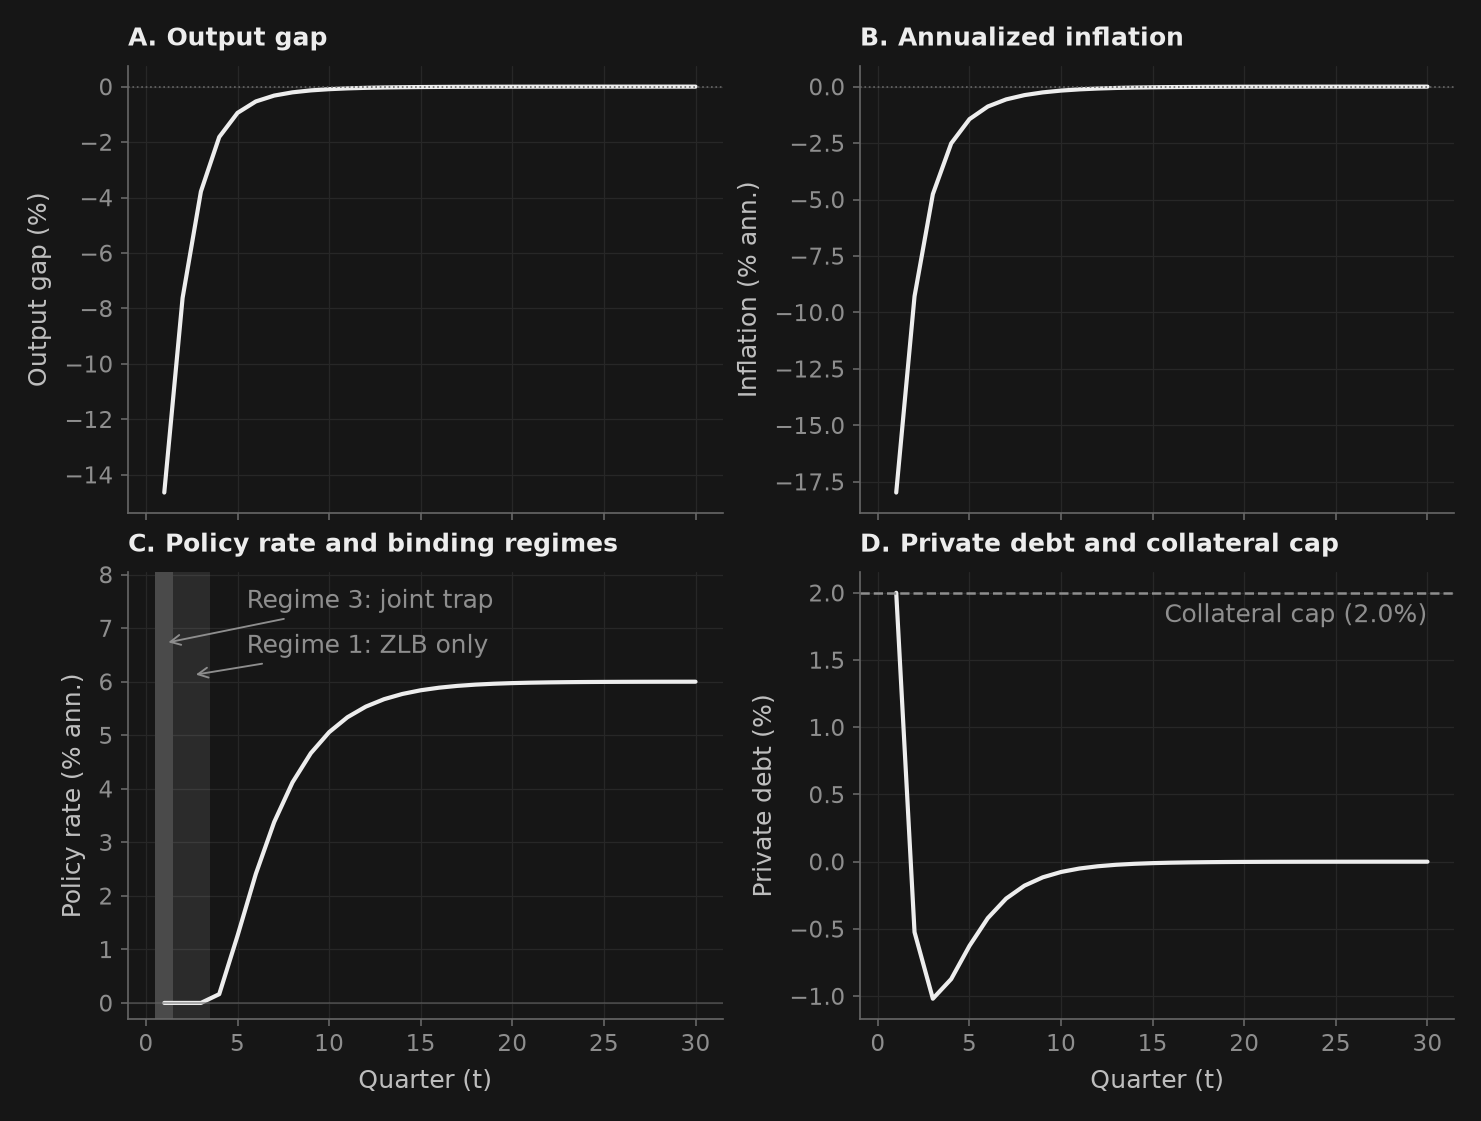

In [7]:
# ==============================================================================
# Simulation 5: Multi-Constraint OccBin Dynamics & 4-Regime Traversal
# ==============================================================================
from puremacro.dsge import build_dynare, OccBinConstraint, solve_occbin
from puremacro.dsge.occbin import solve_multiconstraint_occbin

# Setup a 5-equation New Keynesian DSGE model with endogenous borrowing:
# Variables: y (output gap), pi (inflation), r (policy rate), b (private debt), g (demand shock)
# Shocks: eps_g (demand), eps_r (monetary), eps_b (credit expansion)
params_mc = {
    "beta": 0.99,
    "sigma": 1.0,
    "kappa": 0.15,
    "phi_pi": 1.5,
    "phi_y": 0.25,
    "rho_r": 0.6,
    "rho_b": 0.5,
    "rho_g": 0.7,
    "gamma_y": 0.2,
    "chi": 0.1,
    "r_ss": 0.015,
    "b_bar": 0.02,
}

variables_mc = ["y", "pi", "r", "b", "g"]
shocks_mc = ["eps_g", "eps_r", "eps_b"]
steady_state_mc = {v: 0.0 for v in variables_mc}

# Regime 0: Reference model (Taylor rule active, credit limit slack)
def ref_eqs_mc(lead, curr, lag, shocks_v, p):
    return [
        curr.y - lead.y + (curr.r - lead.pi) / p.sigma - curr.g + p.chi * curr.b,
        curr.pi - p.beta * lead.pi - p.kappa * curr.y,
        curr.r - (p.rho_r * lag.r + (1.0 - p.rho_r) * (p.phi_pi * curr.pi + p.phi_y * curr.y) + shocks_v.eps_r),
        curr.b - (p.rho_b * lag.b + p.gamma_y * curr.y + shocks_v.eps_b),
        curr.g - p.rho_g * lag.g - shocks_v.eps_g,
    ]

# Regime 1: ZLB binding (r pegged to -r_ss, borrowing slack)
def zlb_eqs_mc(lead, curr, lag, shocks_v, p):
    return [
        curr.y - lead.y + (curr.r - lead.pi) / p.sigma - curr.g + p.chi * curr.b,
        curr.pi - p.beta * lead.pi - p.kappa * curr.y,
        curr.r - (-p.r_ss),
        curr.b - (p.rho_b * lag.b + p.gamma_y * curr.y + shocks_v.eps_b),
        curr.g - p.rho_g * lag.g - shocks_v.eps_g,
    ]

# Regime 2: Borrowing limit binding (b pegged to b_bar, Taylor rule active)
def borr_eqs_mc(lead, curr, lag, shocks_v, p):
    return [
        curr.y - lead.y + (curr.r - lead.pi) / p.sigma - curr.g + p.chi * curr.b,
        curr.pi - p.beta * lead.pi - p.kappa * curr.y,
        curr.r - (p.rho_r * lag.r + (1.0 - p.rho_r) * (p.phi_pi * curr.pi + p.phi_y * curr.y) + shocks_v.eps_r),
        curr.b - p.b_bar,
        curr.g - p.rho_g * lag.g - shocks_v.eps_g,
    ]

# Build regimes via puremacro build_dynare
m_uncons_mc = build_dynare(ref_eqs_mc, variables=variables_mc, shocks=shocks_mc, params=params_mc, steady_state=steady_state_mc)
m_zlb_mc = build_dynare(zlb_eqs_mc, variables=variables_mc, shocks=shocks_mc, params=params_mc, steady_state=steady_state_mc, check_steady_state=False, strict=False)
m_borr_mc = build_dynare(borr_eqs_mc, variables=variables_mc, shocks=shocks_mc, params=params_mc, steady_state=steady_state_mc, check_steady_state=False, strict=False)

c_zlb_mc = OccBinConstraint(variable="r", threshold=-params_mc["r_ss"], operator="<")
c_borr_mc = OccBinConstraint(variable="b", threshold=params_mc["b_bar"], operator=">")

# Compound crisis shock at t=1:
# - Deep contractionary demand shock (eps_g = -6.0%) pushing r into ZLB
# - Credit demand expansion shock (eps_b = +5.0%) pushing debt against collateral cap
shocks_multi = np.zeros((horizon, len(shocks_mc)))
shocks_multi[0, 0] = -0.06
shocks_multi[0, 2] = 0.05

res_mc = solve_multiconstraint_occbin(
    m_unconstrained=m_uncons_mc,
    m_constrained_dict={"zlb": m_zlb_mc, "borr": m_borr_mc},
    constraints={"zlb": c_zlb_mc, "borr": c_borr_mc},
    shock_seq=shocks_multi,
    horizon=horizon,
)

print("=" * 76)
print("MULTI-CONSTRAINT OCCBIN SIMULATION SCORECARD (4 REGIMES)")
print("=" * 76)
print(f"Algorithm Convergence : {res_mc.converged} (in {res_mc.iterations} fixed-point iterations)")
print(f"Realized Regime Sequence:")
print(f"  {res_mc.regimes}")
print(f"Regimes Visited       : {sorted(list(set(res_mc.regimes)))} (3=Joint, 1=ZLB only, 0=Slack)")
print(f"Total Binding Periods : {res_mc.binding_periods} quarters")
print(f"Policy Rate Minimum   : {res_mc.simulated_path['r'].min():.6f} (ZLB Floor: {-params_mc['r_ss']:.6f})")
print(f"Debt Peak Level       : {res_mc.simulated_path['b'].max():.6f} (Borrowing Cap: {params_mc['b_bar']:.6f})")
print("=" * 76)

# Verify single-constraint fallback parity bit-for-bit
res_single_mc = solve_occbin(m_uncons_mc, m_zlb_mc, c_zlb_mc, shock_sequence=shocks_multi, horizon=horizon)
res_multi_single_mc = solve_multiconstraint_occbin(m_uncons_mc, {"zlb": m_zlb_mc}, shock_seq=shocks_multi, constraints={"zlb": c_zlb_mc}, horizon=horizon)
assert res_single_mc.regimes == res_multi_single_mc.regimes, "K=1 fallback regimes must match solve_occbin."
assert np.max(np.abs(res_single_mc.simulated_path.values - res_multi_single_mc.simulated_path.values)) < 1e-12, "Fallback paths must match to machine precision."

# Multi-Constraint Visualization
fig, axes = _nbstyle.figura(2, 2, sharex=True)

# Panel A: Output Gap
ax = axes[0, 0]
ax.plot(time, res_mc["y"] * 100, **_nbstyle.S1)
ax.axhline(0, color=_nbstyle.SPINE, linestyle=":", linewidth=0.8)
ax.set_ylabel("Output gap (%)")
ax.set_title("A. Output gap")

# Panel B: Inflation
ax = axes[0, 1]
ax.plot(time, res_mc["pi"] * 400, **_nbstyle.S1)
ax.axhline(0, color=_nbstyle.SPINE, linestyle=":", linewidth=0.8)
ax.set_ylabel("Inflation (% ann.)")
ax.set_title("B. Annualized inflation")

# Panel C: Nominal Policy Rate & ZLB Floor
ax = axes[1, 0]
r_level_mc = (params_mc["r_ss"] + res_mc["r"]) * 400
ax.plot(time, r_level_mc, **_nbstyle.S1)
ax.axhline(0, color=_nbstyle.SPINE, linestyle="-", linewidth=0.8, alpha=0.6)
for t_idx, reg_val in enumerate(res_mc.regimes):
    if reg_val == 3:
        ax.axvspan(t_idx + 0.5, t_idx + 1.5, color=_nbstyle.tono(0.28), lw=0)
    elif reg_val == 1:
        ax.axvspan(t_idx + 0.5, t_idx + 1.5, color=_nbstyle.RECESION, lw=0)
# Each band is named from above, where the rate has not lifted off yet
r_top = r_level_mc.max()
t_reg3 = [t + 1 for t, reg in enumerate(res_mc.regimes) if reg == 3]
t_reg1 = [t + 1 for t, reg in enumerate(res_mc.regimes) if reg == 1]
ax.set_ylim(top=r_top * 1.34)
ax.annotate("Regime 3: joint trap", xy=(np.mean(t_reg3), r_top * 1.12), xytext=(5.5, r_top * 1.25),
            ha="left", va="center", color=_nbstyle.NOTA, arrowprops=_nbstyle.FLECHA)
ax.annotate("Regime 1: ZLB only", xy=(np.mean(t_reg1), r_top * 1.02), xytext=(5.5, r_top * 1.11),
            ha="left", va="center", color=_nbstyle.NOTA, arrowprops=_nbstyle.FLECHA)
ax.set_xlabel("Quarter (t)")
ax.set_ylabel("Policy rate (% ann.)")
ax.set_title("C. Policy rate and binding regimes")

# Panel D: Borrowing & Collateral Cap
ax = axes[1, 1]
ax.plot(time, res_mc["b"] * 100, **_nbstyle.S1)
ax.axhline(params_mc["b_bar"] * 100, color=_nbstyle.NOTA, linestyle="--", linewidth=1.2)
ax.annotate(f"Collateral cap ({params_mc['b_bar'] * 100:.1f}%)", xy=(time[-1], params_mc["b_bar"] * 100), xytext=(0, -5),
            textcoords="offset points", ha="right", va="top", color=_nbstyle.NOTA)
ax.set_xlabel("Quarter (t)")
ax.set_ylabel("Private debt (%)")
ax.set_title("D. Private debt and collateral cap")

plt.show()

# Print formatted Markdown publication table excerpt
print("\nMulti-Constraint Trajectory Table (Markdown format):")
print(res_mc.to_markdown(digits=4, index=False))


## 7. Filtering states when the regime changes

A Kalman filter can handle time-varying matrices when they are known. The difficulty here is that the regime depends on unobserved states. The piecewise filter alternates between a regime path and Gaussian updates conditional on that path.

Summing Gaussian contributions gives an **approximate likelihood conditional on the regime treatment**, not exact integration over all regime uncertainty. It is also not a Bayesian marginal likelihood: $p(Y\mid\theta)$ holds parameters fixed, while $p(Y)$ integrates over them.

The following data come from a reduced-form simulation with a truncated rule, not the same rational-expectations equations fitted by the filter. Use them to compare filter behavior, not as structural recovery or evidence about 2008.

PIECEWISE KALMAN FILTER STATE ESTIMATION SCORECARD
PKF Log-Likelihood ln L(Y|theta)    :    56.87
Linear Kalman Log-Likelihood        :     9.93
Likelihood Gain from Modeling ZLB   :   +46.94 log-points
Detected ZLB Quarters               : 9 out of 30 quarters
Filter Convergence Across Periods   : True

PIECEWISE KALMAN FILTER REPORT (Giovannini, Pfeiffer & Ratto 2021)
Log-likelihood     : 56.866733
Observations       : 30
Constraint regimes : 9 period(s) binding (30.0%)
Regime convergence : Verified
Recent regimes     : [1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
------------------------------------------------------------------------------
FILTERED STATE SUMMARY STATISTICS
------------------------------------------------------------------------------
    Initial (t=1)       Min       Max      Mean  Final (t=T)
y             0.0 -0.102985  0.011598 -0.019069     0.002744
pi            0.0 -0.031211  0.004126 -0.006048     0.001550
r             0.0 -0.010000  0.00441

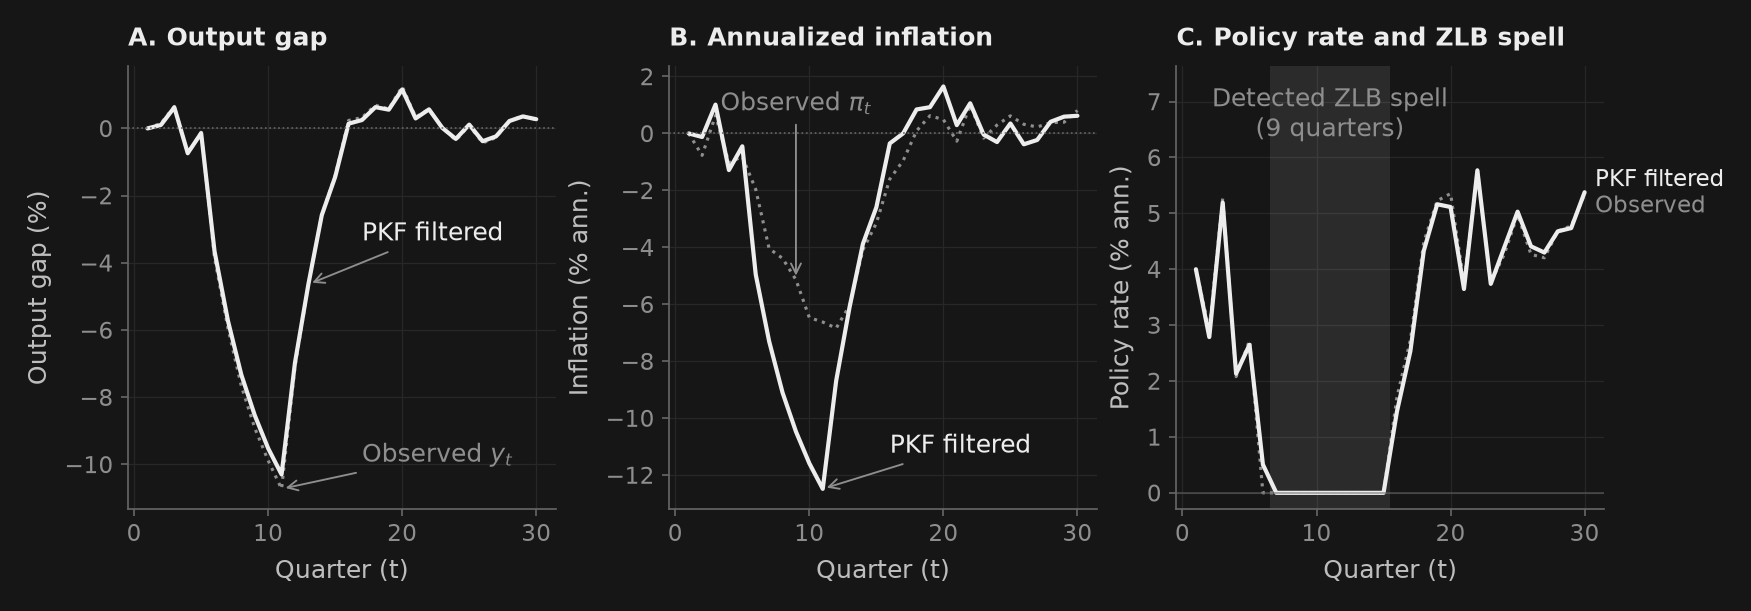

In [8]:
# ==============================================================================
# Simulation 6: Piecewise Kalman Filter State Estimation & Likelihood Evaluation
# ==============================================================================
from puremacro.dsge.occbin import piecewise_kalman_filter
from puremacro.state_space import kalman_filter
from puremacro.dsge import make_state_space_from_varobs

# Generate a realistic 30-quarter macroeconomic dataset featuring a severe liquidity trap
# grounded in post-2008 dynamics (where policy rates hit and stay at the floor)
rng = np.random.default_rng(42)
T_pkf = 30
dates_pkf = pd.date_range("2008-01-01", periods=T_pkf, freq="QS")

y_sim = np.zeros(T_pkf)
pi_sim = np.zeros(T_pkf)
r_sim = np.zeros(T_pkf)

# Illustrative reduced-form DGP with deep demand contraction between t=5 and t=10
for t in range(1, T_pkf):
    sg = -0.04 if 5 <= t <= 10 else rng.normal(0, 0.005)
    y_sim[t] = 0.7 * y_sim[t - 1] - (r_sim[t - 1] - 0.5 * pi_sim[t - 1]) + sg
    pi_sim[t] = 0.5 * pi_sim[t - 1] + 0.1 * y_sim[t] + rng.normal(0, 0.002)
    notional_r = 1.5 * pi_sim[t] + 0.125 * y_sim[t]
    r_sim[t] = max(-r_ss, notional_r)

data_pkf = pd.DataFrame({"y": y_sim, "pi": pi_sim, "r": r_sim}, index=dates_pkf)

# Measurement error covariance: sd=0.01 in model units (100 bp for a quarterly rate)
H_meas = 1e-4 * np.eye(3)

# 1. Evaluate Piecewise Kalman Filter (PKF)
res_pkf = piecewise_kalman_filter(
    m_unconstrained=ref_model,
    m_constrained_dict={"zlb": cons_model},
    data=data_pkf,
    varobs=["y", "pi", "r"],
    constraints={"zlb": constraint},
    H=H_meas,
    horizon=25,
)

# Unpacking contract test
ll_pkf, filtered_states_pkf, regimes_pkf = res_pkf

# 2. Evaluate Linear Kalman Filter on identical data
ssm = make_state_space_from_varobs(ref_model, varobs=["y", "pi", "r"])
ssm.H = H_meas
out_lin_kalman = kalman_filter(data_pkf.values, ssm)
ll_linear = out_lin_kalman["loglik"]

loglik_gain = res_pkf.log_likelihood - ll_linear
n_binding_pkf = sum(r > 0 for r in res_pkf.regimes)

print("=" * 76)
print("PIECEWISE KALMAN FILTER STATE ESTIMATION SCORECARD")
print("=" * 76)
print(f"PKF Log-Likelihood ln L(Y|theta)    : {res_pkf.log_likelihood:8.2f}")
print(f"Linear Kalman Log-Likelihood        : {ll_linear:8.2f}")
print(f"Likelihood Gain from Modeling ZLB   : {loglik_gain:+8.2f} log-points")
print(f"Detected ZLB Quarters               : {n_binding_pkf} out of {T_pkf} quarters")
print(f"Filter Convergence Across Periods   : {res_pkf.converged}")
print("=" * 76)

# Print publication-grade PKF summary
print("\n" + res_pkf.summary())

# Visualization: Filtered States vs Observed Data & ZLB Regime Detection
fig, axes = _nbstyle.figura(1, 3)
time_pkf = np.arange(1, T_pkf + 1)
reg_arr = np.asarray(res_pkf.regimes)

# Panel 1: Filtered Output Gap
ax = axes[0]
y_obs = data_pkf["y"] * 100
y_filt = res_pkf.filtered_states["y"] * 100
ax.plot(time_pkf, y_obs, color=_nbstyle.NOTA, linestyle=":", linewidth=1.5)
ax.plot(time_pkf, y_filt, **_nbstyle.S1)
ax.axhline(0, color=_nbstyle.SPINE, linestyle=":", linewidth=0.8)
# The two series almost coincide: each one is named in the slump, where the dotted line shows under the solid one
i_min = int(np.argmin(y_filt.values))
ax.annotate("PKF filtered", xy=(time_pkf[i_min + 2], y_filt.iloc[i_min + 2]), xytext=(time_pkf[i_min + 6], y_filt.iloc[i_min + 2] + 1.5),
            ha="left", va="center", color=_nbstyle.S1["color"], arrowprops=_nbstyle.FLECHA)
ax.annotate("Observed $y_t$", xy=(time_pkf[i_min], y_obs.iloc[i_min]), xytext=(time_pkf[i_min] + 6, y_obs.iloc[i_min] + 1.0),
            ha="left", va="center", color=_nbstyle.NOTA, arrowprops=_nbstyle.FLECHA)
ax.set_xlabel("Quarter (t)")
ax.set_ylabel("Output gap (%)")
ax.set_title("A. Output gap")

# Panel 2: Filtered Inflation
ax = axes[1]
pi_obs = data_pkf["pi"] * 400
pi_filt = res_pkf.filtered_states["pi"] * 400
ax.plot(time_pkf, pi_obs, color=_nbstyle.NOTA, linestyle=":", linewidth=1.5)
ax.plot(time_pkf, pi_filt, **_nbstyle.S1)
ax.axhline(0, color=_nbstyle.SPINE, linestyle=":", linewidth=0.8)
# The two series part inside the trap: each one is named where they differ most
i_min = int(np.argmin(pi_filt.values))
ax.annotate("Observed $\\pi_t$", xy=(time_pkf[i_min - 2], pi_obs.iloc[i_min - 2]), xytext=(time_pkf[i_min - 2], 0.6),
            ha="center", va="bottom", color=_nbstyle.NOTA, arrowprops=_nbstyle.FLECHA)
ax.annotate("PKF filtered", xy=(time_pkf[i_min], pi_filt.iloc[i_min]), xytext=(time_pkf[i_min] + 5, pi_filt.iloc[i_min] + 1.5),
            ha="left", va="center", color=_nbstyle.S1["color"], arrowprops=_nbstyle.FLECHA)
ax.set_xlabel("Quarter (t)")
ax.set_ylabel("Inflation (% ann.)")
ax.set_title("B. Annualized inflation")

# Panel 3: Policy Rate Tracking & Shaded ZLB Spells
ax = axes[2]
r_obs_lev = (r_ss + data_pkf["r"]) * 400
r_filt_lev = (r_ss + res_pkf.filtered_states["r"]) * 400
ax.plot(time_pkf, r_obs_lev, label="Observed", color=_nbstyle.NOTA, linestyle=":", linewidth=1.5)
ax.plot(time_pkf, r_filt_lev, label="PKF filtered", **_nbstyle.S1)
ax.axhline(0, color=_nbstyle.SPINE, linestyle="-", linewidth=0.8, alpha=0.6)

# Highlight detected ZLB spells
for s_idx in range(len(reg_arr)):
    if reg_arr[s_idx] > 0:
        ax.axvspan(s_idx + 0.5, s_idx + 1.5, color=_nbstyle.RECESION, lw=0)
t_zlb = time_pkf[reg_arr > 0]
# The shaded spell is named above the paths, where no line reaches the text
r_top_pkf = max(r_obs_lev.max(), r_filt_lev.max())
ax.set_ylim(top=r_top_pkf * 1.32)
ax.annotate(f"Detected ZLB spell\n({len(t_zlb)} quarters)", xy=(t_zlb.mean(), r_top_pkf * 1.17),
            ha="center", va="center", color=_nbstyle.NOTA)

ax.set_xlabel("Quarter (t)")
ax.set_ylabel("Policy rate (% ann.)")
ax.set_title("C. Policy rate and ZLB spell")
_nbstyle.etiquetar(ax, donde="fin")   # the two series coincide: their names go outside, next to the last point

plt.show()

## 8. Bridge to Topic 4: RBC with irreversible investment

The Oi–Hartman–Abel example holds wages fixed to isolate flexible labor. We now close **general equilibrium**: the household chooses consumption, labor and capital, and installed investment cannot be converted back into consumption. The question is **when this constraint binds and how it changes the recovery**.

With no trend growth, the planner solves
\[
\max E_0\sum_{t=0}^{\infty}\beta^t\left[\frac{c_t^{1-\sigma}}{1-\sigma}+\mu\frac{(1-l_t)^{1-\nu}}{1-\nu}\right],
\]
using the logarithmic limit when $\sigma=1$, subject to
\[
y_t=e^{a_t}k_{t-1}^{\alpha}l_t^{1-\alpha},\quad c_t+i_t=y_t,\quad
k_t=(1-\delta)k_{t-1}+i_t,\quad \boxed{i_t\geq0},\qquad
a_t=\rho_a a_{t-1}+\varepsilon_t.
\]
The restriction applies to **gross investment**: capital can still fall through depreciation. We start at the deterministic steady state, where $\bar i=\delta\bar k>0$ and the constraint is slack. The parameter $\mu$ is calibrated to $\bar l=0.33$.

### Kuhn–Tucker: why the future multiplier appears

Substituting $i_t=k_t-(1-\delta)k_{t-1}$, let $\lambda_t$ be the resource multiplier and $\eta_t\geq0$ the irreversibility multiplier. The period Lagrangian is
\[
u(c_t,l_t)+\lambda_t\left[y_t+(1-\delta)k_{t-1}-c_t-k_t\right]
+\eta_t\left[k_t-(1-\delta)k_{t-1}\right].
\]
The consumption, labor and capital conditions are
\[
\lambda_t=c_t^{-\sigma},\qquad
\mu(1-l_t)^{-\nu}=\lambda_t(1-\alpha)\frac{y_t}{l_t},
\]
\[
\boxed{\lambda_t-\eta_t=\beta E_t\left[\lambda_{t+1}
\left(\alpha\frac{y_{t+1}}{k_t}+1-\delta\right)-(1-\delta)\eta_{t+1}\right]},
\qquad i_t\geq0,\quad\eta_t\geq0,\quad\eta_t i_t=0.
\]
**Adding only a current multiplier to the usual Euler equation is incorrect.** Raising $k_t$ increases the capital that must be retained tomorrow, which produces the term $-(1-\delta)\eta_{t+1}$.

For interpretation, define $\xi_t=\eta_t/\lambda_t$, $q_t^K=1-\xi_t$ and $M_{t,t+1}=\beta\lambda_{t+1}/\lambda_t$:
\[
q_t^K=E_t\left[M_{t,t+1}\left(\alpha\frac{y_{t+1}}{k_t}+(1-\delta)q_{t+1}^K\right)\right],
\qquad q_t^K\leq1,\quad i_t\geq0,\quad(1-q_t^K)i_t=0.
\]
When $i_t>0$, the marginal value of capital equals its replacement cost: $q_t^K=1$. When $q_t^K<1$, selling capital would be desirable, but the constraint forces $i_t=0$. Here $q^K$ is a shadow value, not the investment-efficiency shock in Topic 4.

Labor can still adjust after observing $A_t=e^{a_t}$. At a fixed wage, operating profits would be $B(w_t)k_{t-1}A_t^{1/\alpha}$, as in the slides. Here $w_t$, $c_t$ and the discount factor $M_{t,t+1}$ are jointly determined: that convexity identifies a partial incentive, not the sign of aggregate investment.

Methodological reference: [Guerrieri and Iacoviello (2015)](https://www.matteoiacoviello.com/research_files/JME_2015.pdf), who also study an RBC model with an investment floor. This application retains endogenous labor and uses full irreversibility $i_t\geq0$; it does not reproduce their calibration.

### 8.1. The two regimes passed to OccBin

For $x\in\{y,c,k,l\}$ we use proportional **level deviations**, $\hat x_t=(x_t-\bar x)/\bar x$. For investment we use
\[
j_t\equiv\frac{i_t-\bar i}{\bar k},\qquad i_t\geq0\iff j_t\geq-\delta.
\]
We do not take $\log i_t$: it does not exist at $i_t=0$. In the code, `y,c,k,l` stand for hatted deviations; `a` is log TFP and `xi` is the first-order approximation to $\eta_t/\lambda_t$.

Let $\bar r=1/\beta-1+\delta=\alpha\bar y/\bar k$. Both regimes share
\[
\begin{aligned}
a_t&=\rho_a a_{t-1}+\varepsilon_t,\\
\hat y_t&=a_t+\alpha\hat k_{t-1}+(1-\alpha)\hat l_t,\\
\sigma\hat c_t+\left(1+\nu\frac{\bar l}{1-\bar l}\right)\hat l_t&=\hat y_t,\\
\frac{\bar y}{\bar k}\hat y_t&=\frac{\bar c}{\bar k}\hat c_t+j_t,\\
\hat k_t&=(1-\delta)\hat k_{t-1}+j_t,\\
\sigma(E_t\hat c_{t+1}-\hat c_t)-\xi_t+\beta(1-\delta)E_t\xi_{t+1}
-\beta\bar r(E_t\hat y_{t+1}-\hat k_t)&=0.
\end{aligned}
\]
The seventh equation is **$\xi_t=0$** in the slack regime and **$j_t=-\delta$** in the binding regime. Bind if the slack regime proposes $j_t<-\delta$; relax if the binding regime gives $\xi_t<0$. We therefore explicitly set `relax_variable="xi"`: comparing investment already pinned to its floor does not verify the multiplier's sign.

Both systems are approximated around the **same slack steady state**. The binding regime retains the constant $\delta$ and is not solved around a separate steady state.

In [9]:
rbc_labels = {'sweep_columns': ['Log-TFP innovation',
                   'TFP change (%)',
                   'Linear i₀/ȳ (%)',
                   'OccBin i₀/ȳ (%)',
                   'Periods i=0 (OccBin)'],
 'nonlinear': 'Nonlinear',
 'linear': 'Unconstrained linear',
 'comparison_columns': ['Log-TFP innovation',
                        'Method',
                        'Periods i=0',
                        'c₀: deviation (%)',
                        'y₀: deviation (%)',
                        'Maximum ξ'],
 'nonlinear_error': 'Maximum nonlinear residual:',
 'investment_axis': 'Gross investment (% of ȳ)',
 'consumption_axis': 'Consumption: dev. from SS (%)',
 'time_axis': 'Quarters after the shock',
 'audit_ok': 'RBC: feasibility, complementarity, Euler, horizon and linear equivalence verified.',
 'terminal_error': 'Maximum change from doubling horizon (first 40 periods):'}

# RBC: the seven equations above, with one switching equation.
from puremacro.dsge import build_dynare, solve_occbin, OccBinConstraint

rbc_p = dict(alpha=0.33, beta=0.99, delta=0.025, sigma=1.0,
             nu=1.5, lbar=0.33, rho=0.95)
rbc_p["rbar"] = 1 / rbc_p["beta"] - 1 + rbc_p["delta"]
rbc_p["yk"] = rbc_p["rbar"] / rbc_p["alpha"]
rbc_p["ck"] = rbc_p["yk"] - rbc_p["delta"]
rbc_p["lab"] = 1 + rbc_p["nu"] * rbc_p["lbar"] / (1 - rbc_p["lbar"])
rbc_kbar = rbc_p["lbar"] * (rbc_p["alpha"] / rbc_p["rbar"])**(1 / (1-rbc_p["alpha"]))
rbc_cbar = rbc_p["ck"] * rbc_kbar
rbc_mu = ((1-rbc_p["alpha"]) * rbc_p["yk"] * rbc_kbar / rbc_p["lbar"]
          * rbc_cbar**(-rbc_p["sigma"]) * (1-rbc_p["lbar"])**rbc_p["nu"])
rbc_vars = ["a", "k", "c", "l", "y", "j", "xi"]

def rbc_equations(lead, curr, lag, shocks, p):
    return [curr.a - p.rho * lag.a - shocks.e_a,
            curr.y - curr.a - p.alpha * lag.k - (1-p.alpha) * curr.l,
            p.sigma * curr.c + p.lab * curr.l - curr.y,
            p.yk * curr.y - p.ck * curr.c - curr.j,
            curr.k - (1-p.delta) * lag.k - curr.j,
            p.sigma * (lead.c-curr.c) - curr.xi + p.beta * (1-p.delta) * lead.xi
            - p.beta * p.rbar * (lead.y-curr.k),
            curr.xi]

def rbc_binding_equations(lead, curr, lag, shocks, p):
    residuals = rbc_equations(lead, curr, lag, shocks, p)
    residuals[-1] = curr.j + p.delta
    return residuals

def make_rbc_models(p, innovation_sd=0.007):
    args = dict(variables=rbc_vars, shocks=["e_a"], params=p,
                steady_state={v: 0.0 for v in rbc_vars},
                shock_cov=np.array([[innovation_sd**2]]))
    ref = build_dynare(rbc_equations, **args)
    # Common expansion point: it deliberately does not satisfy j = -delta.
    binding = build_dynare(rbc_binding_equations, **args,
                          check_steady_state=False, strict=False)
    constraint = OccBinConstraint(variable="j", threshold=-p["delta"], operator="<",
                                  relax_variable="xi", relax_threshold=0.0,
                                  relax_operator="<")
    return ref, binding, constraint

rbc_ref, rbc_bind, rbc_constraint = make_rbc_models(rbc_p)
rbc_H, rbc_stress = 160, -0.30  # Deliberately large stress; log TFP units.
rbc_dr = rbc_ref.decision_rules()
rbc_P = np.zeros((len(rbc_vars), len(rbc_vars)))
for state in rbc_ref.states:
    rbc_P[:, rbc_vars.index(state)] = rbc_dr.ghx[state].to_numpy()

def rbc_linear_path(innovation, H=rbc_H):
    path = np.zeros((H, len(rbc_vars)))
    path[0] = rbc_dr.ghu.to_numpy()[:, 0] * innovation
    for t in range(1, H):
        path[t] = rbc_P @ path[t-1]
    return pd.DataFrame(path, columns=rbc_vars)

def rbc_occbin_path(innovation, H=rbc_H):
    result = solve_occbin(rbc_ref, rbc_bind, rbc_constraint,
                         shock_sequence=np.array([innovation]), horizon=H, max_iter=100)
    assert result.converged, "RBC regime iteration or terminal condition failed"
    return result

rbc_occ = rbc_occbin_path(rbc_stress)
rbc_linear = rbc_linear_path(rbc_stress)
print(pd.Series({**rbc_p, "kbar": rbc_kbar, "cbar": rbc_cbar, "mu": rbc_mu}).round(6))

alpha    0.330000
beta     0.990000
delta    0.025000
sigma    1.000000
nu       1.500000
lbar     0.330000
rho      0.950000
rbar     0.035101
yk       0.106367
ck       0.081367
lab      1.738806
kbar     9.354978
cbar     0.761184
mu       1.455567
dtype: float64


### 8.2. A realized shock and a stress experiment

The innovation arrives unexpectedly at $t=0$; thereafter agents expect zero future innovations and $a_t=\rho_a^t\varepsilon_0$. This is a **conditional perfect-foresight path**, not a GIRF integrating over future shocks.

**Predict:** starting from $\bar i=\delta\bar k>0$, must a typical 0.7% shock activate $i_t=0$? Which variable verifies that leaving the binding regime is optimal?

The table varies the shock size while retaining the calibration. The stress case uses $\varepsilon_0=-0.30$ in log TFP: a level decline of $100(e^{-0.30}-1)\simeq-25.9\%$. This is deliberately extreme, not a typical fluctuation or a calibration of the uncertainty effect. A 30-log-point decline requires checking the accuracy of the local approximation.

In [10]:
rbc_sweep_rows = []
for innovation in [-0.007, -0.05, -0.10, -0.20, -0.25, rbc_stress]:
    result = rbc_occbin_path(innovation)
    linear = rbc_linear_path(innovation)
    rbc_sweep_rows.append([innovation, 100*np.expm1(innovation),
                          100*(rbc_p["delta"]+linear["j"].iloc[0])/rbc_p["yk"],
                          100*(rbc_p["delta"]+result["j"].iloc[0])/rbc_p["yk"],
                          result.binding_periods])
rbc_sweep = pd.DataFrame(rbc_sweep_rows, columns=rbc_labels["sweep_columns"])
display(rbc_sweep.round(4))

,Log-TFP innovation,TFP change (%),Linear i₀/ȳ (%),OccBin i₀/ȳ (%),Periods i=0 (OccBin)
0,-0.007,-0.6976,22.7539,22.7539,0
1,-0.050,-4.8771,18.1484,18.1484,0
2,-0.100,-9.5163,12.7931,12.7931,0
3,-0.200,-18.1269,2.0827,2.0827,0
4,-0.250,-22.1199,-3.2725,0.0000,2
5,-0.300,-25.9182,-8.6278,0.0000,5


### 8.3. Checking the approximation: the same conditions without linearizing them

OccBin solves the piecewise equations, but their coefficients come from first-order approximations. **Algorithmic convergence does not establish the accuracy of the economic approximation.**

The following benchmark solves the nonlinear perfect-foresight conditions and complementarity using
\[
\sqrt{(j_t+\delta)^2+\xi_t^2}-(j_t+\delta)-\xi_t=0.
\]
This equality is equivalent to $j_t+\delta\geq0$, $\xi_t\geq0$ and $(j_t+\delta)\xi_t=0$. OccBin supplies the initial path. At the horizon we use the slack regime's stable rule as a local terminal condition; doubling the horizon verifies that this closure does not move the first 40 periods. **This benchmark also does not integrate future risk.**

The table includes the $-0.25$ shock: close to the boundary, the methods may disagree even about whether the constraint binds. We do not require the same number of binding periods from both methods.

The nonlinear solve now uses `solve_transition`: continuation, economic domains, explicit assignment of investment complementarity to `xi`, and the stable linear terminal policy. We retain the independent residual function and horizon-doubling check.


In [11]:

# These are the nonlinear FOCs, written in proportional level deviations.
def rbc_exact_residuals(X, innovation, p=rbc_p):
    H = len(X)
    lag = np.vstack([np.zeros(len(rbc_vars)), X[:-1]])
    lead = np.vstack([X[1:], rbc_P @ X[-1]])
    a, k, c, l, y, j, xi = X.T
    eps = np.zeros(H)
    eps[0] = innovation
    M = p["beta"] * ((1+lead[:, 2])/(1+c))**(-p["sigma"])
    return np.column_stack([
        a-p["rho"]*lag[:, 0]-eps,
        (1+y)-np.exp(a)*(1+lag[:, 1])**p["alpha"]*(1+l)**(1-p["alpha"]),
        (1+c)**p["sigma"]*((1-p["lbar"]*(1+l))/(1-p["lbar"]))**(-p["nu"])
        -(1+y)/(1+l),
        p["yk"]*y-p["ck"]*c-j,
        k-(1-p["delta"])*lag[:, 1]-j,
        1-xi-M*(p["rbar"]*(1+lead[:, 4])/(1+k)+(1-p["delta"])*(1-lead[:, 6])),
        np.hypot(j+p["delta"], xi)-(j+p["delta"])-xi,
    ])

from puremacro.dsge import solve_transition

def rbc_period_equations(lead, current, lag, innovation):
    a, k, c, l, y, j, xi = current
    p = rbc_p
    M = p["beta"]*((1+lead[2])/(1+c))**(-p["sigma"])
    return np.array([
        a-p["rho"]*lag[0]-np.asarray(innovation).reshape(-1)[0],
        (1+y)-np.exp(a)*(1+lag[1])**p["alpha"]*(1+l)**(1-p["alpha"]),
        (1+c)**p["sigma"]*((1-p["lbar"]*(1+l))/(1-p["lbar"]))**(-p["nu"])-(1+y)/(1+l),
        p["yk"]*y-p["ck"]*c-j,
        k-(1-p["delta"])*lag[1]-j,
        1-xi-M*(p["rbar"]*(1+lead[4])/(1+k)+(1-p["delta"])*(1-lead[6])),
        j+p["delta"],  # Investment gap complementary to xi >= 0.
    ])

def rbc_nonlinear_path(innovation, H=rbc_H):
    shocks = np.zeros((H, 1))
    shocks[0, 0] = innovation
    start = rbc_occbin_path(innovation, H).simulated_path.to_numpy()
    transition = solve_transition(
        rbc_period_equations, y_init=np.zeros(len(rbc_vars)), y_end=np.zeros(len(rbc_vars)),
        shocks=shocks, variable_names=rbc_vars, initial_path=start,
        mcp=True, mcp_bounds={"xi": (0.0, None)}, mcp_equations={"xi": (6, 1)},
        terminal_policy=lambda last: rbc_P @ last, terminal_jacobian=lambda last: rbc_P,
        variable_bounds={"k": (-.95, None), "c": (-.95, None),
                         "y": (-.95, None), "l": (-.95, 1/rbc_p["lbar"]-1-.01)},
        method="central", tol=1e-10, max_iter=100, max_solves=40,
    )
    assert transition.converged, transition.summary()
    X = transition.path.to_numpy()
    error = np.max(np.abs(rbc_exact_residuals(X, innovation)))
    assert error < 1e-8, error
    return pd.DataFrame(X, columns=rbc_vars), error

rbc_nl, rbc_nl_error = rbc_nonlinear_path(rbc_stress)
rbc_nl_edge, rbc_edge_error = rbc_nonlinear_path(-0.25)
rbc_comparison_rows = []
for innovation, nonlinear in [(-0.25, rbc_nl_edge), (rbc_stress, rbc_nl)]:
    occ = rbc_occbin_path(innovation)
    for method, path, periods in [
        ("OccBin", occ.simulated_path, occ.binding_periods),
        (rbc_labels["nonlinear"], nonlinear, int((nonlinear["xi"] > 1e-7).sum()))]:
        rbc_comparison_rows.append([innovation, method, periods, 100*path["c"].iloc[0],
                                   100*path["y"].iloc[0], path["xi"].max()])
rbc_comparison = pd.DataFrame(rbc_comparison_rows, columns=rbc_labels["comparison_columns"])
display(rbc_comparison.round(4))
print(rbc_labels["nonlinear_error"], f"{max(rbc_nl_error, rbc_edge_error):.2e}")

Maximum nonlinear residual: 3.69e-12


,Log-TFP innovation,Method,Periods i=0,c₀: deviation (%),y₀: deviation (%),Maximum ξ
0,-0.25,OccBin,2,-12.3349,-32.9393,0.0258
1,-0.25,Nonlinear,0,-9.1226,-29.8374,0.0000
2,-0.30,OccBin,5,-18.1792,-37.4101,0.0697
3,-0.30,Nonlinear,2,-13.0922,-33.5187,0.0285


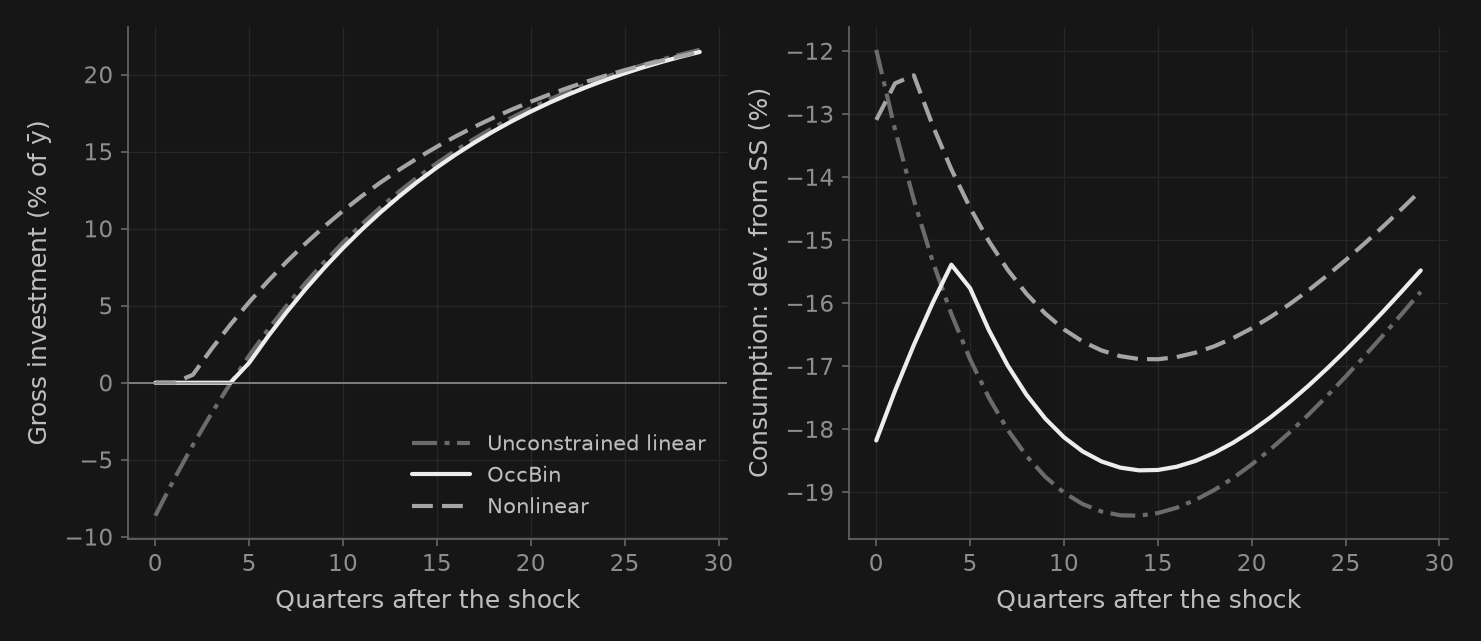

In [12]:
# A fixed-size technology shock; all curves start from the same steady state.
fig, axes = _nbstyle.figura(1, 2, figsize=(plt.rcParams["figure.figsize"]
                               if _nbstyle.PERFIL == "lamina" else None))
rbc_show = 30
rbc_t = np.arange(rbc_show)
rbc_paths = [(rbc_linear, rbc_labels["linear"], _nbstyle.S3),
             (rbc_occ.simulated_path, "OccBin", _nbstyle.S1),
             (rbc_nl, rbc_labels["nonlinear"], _nbstyle.S2)]
for path, label, style in rbc_paths:
    axes[0].plot(rbc_t, 100*(rbc_p["delta"]+path["j"].iloc[:rbc_show])/rbc_p["yk"],
                 label=label, **style)
    axes[1].plot(rbc_t, 100*path["c"].iloc[:rbc_show], label=label, **style)
axes[0].axhline(0, color=_nbstyle.NOTA, lw=.8)
axes[0].set_ylabel(rbc_labels["investment_axis"])
axes[1].set_ylabel(rbc_labels["consumption_axis"])
for ax in axes:
    ax.set_xlabel(rbc_labels["time_axis"])
axes[0].legend(frameon=False, fontsize="small", loc="lower right")
plt.show()

### 8.4. What this RBC teaches about Oi–Hartman–Abel and uncertainty

1. **Irreversibility changes the transmission of a realized shock.** At the floor, investment cannot fall below zero, capital remains installed, and consumption and labor adjust. This does not imply amplification of every negative shock in every variable.
2. **OccBin does not compute Jensen effects or the option to wait due to unrealized future risk.** It uses a first-order approximation within each regime and assumes zero future innovations along these paths. Changing the innovation covariance while keeping the realized impulse fixed leaves the path unchanged; enlarging the impulse does change it, but that is a different experiment.
3. **A pure volatility shock requires nonlinear expectations.** Section 9 adds volatility as a state and solves the stochastic Bellman equation with puremacro, respecting $i\geq0$. A smooth third-order perturbation alone does not solve the irreversibility boundary.

**Interpreting the calibration:** a zero gross-investment floor lies far from the steady state. If it binds only after extreme TFP declines, aggregate irreversibility in this RBC is insufficient to explain frequent inaction. Firm heterogeneity or partial irreversibility are extensions that must be modeled explicitly, not reasons to reinterpret this experiment as an uncertainty shock.

**Exercises:**
- Reduce $\delta$ from 0.025 to 0.01, rebuild the models, and repeat the sweep and nonlinear benchmark. Does the floor move closer to the steady state?
- Change $\rho_a$ and distinguish shock persistence from the duration of the binding regime.
- Explain why $q_t^K<1$ implies inaction and why $i_t=0$ permits $k_t<k_{t-1}$.
- Can an identical path after doubling the innovation standard deviation establish that uncertainty is economically irrelevant? Identify the approximation that removes that channel.

The following audit checks feasibility, multipliers, complementarity, equations, the terminal closure and recovery of the linear model when the constraint is slack.

In [13]:
# Feasibility, complementarity, and the common resource/capital equations.
for path in [rbc_occ.simulated_path, rbc_nl]:
    investment = rbc_p["delta"] + path["j"].to_numpy()
    xi = path["xi"].to_numpy()
    assert investment.min() > -1e-8 and xi.min() > -1e-8
    assert np.max(np.abs(investment*xi)) < 1e-8
    np.testing.assert_allclose(rbc_p["yk"]*path["y"]-rbc_p["ck"]*path["c"], path["j"], atol=1e-8)
    lag_k = np.r_[0, path["k"].to_numpy()[:-1]]
    np.testing.assert_allclose(path["k"], (1-rbc_p["delta"])*lag_k+path["j"], atol=1e-8)
    assert (1+path[["k", "c", "y", "l"]]).to_numpy().min() > 0
    assert (rbc_p["lbar"]*(1+path["l"])).max() < 1

for innovation in [-0.007, 0.007]:
    small = rbc_occbin_path(innovation)
    assert small.binding_periods == 0
    np.testing.assert_allclose(small.simulated_path, rbc_linear_path(innovation), atol=1e-10)
assert rbc_occ.regimes[-1] == 0 and rbc_occ.binding_periods > 0

# Independent check: the nonlinear FOCs linearize to the equations supplied to OccBin.
from types import SimpleNamespace
rbc_direction = np.random.default_rng(724).normal(size=(5, len(rbc_vars)))
rbc_direction[:, -1] = 0  # Slack complementarity: both systems impose xi=0.
rbc_h = 1e-5
rbc_fd = (rbc_exact_residuals(rbc_h*rbc_direction, 0)
          - rbc_exact_residuals(-rbc_h*rbc_direction, 0))/(2*rbc_h)
rbc_step = lambda row: SimpleNamespace(**dict(zip(rbc_vars, row)))
rbc_lag = np.vstack([np.zeros(len(rbc_vars)), rbc_direction[:-1]])
rbc_lead = np.vstack([rbc_direction[1:], rbc_P@rbc_direction[-1]])
for t in range(len(rbc_direction)):
    local = rbc_equations(rbc_step(rbc_lead[t]), rbc_step(rbc_direction[t]),
                          rbc_step(rbc_lag[t]), SimpleNamespace(e_a=0), SimpleNamespace(**rbc_p))
    # The exact q Euler residual has the same sign as our linear Euler residual.
    np.testing.assert_allclose(rbc_fd[t, :6], local[:6], atol=2e-8, rtol=2e-7)
# Check the future multiplier coefficient explicitly, without imposing xi=0.
rbc_future_xi = np.zeros((3, len(rbc_vars)))
rbc_future_xi[1, -1] = 1
rbc_dxi = (rbc_exact_residuals(rbc_h*rbc_future_xi, 0)
           - rbc_exact_residuals(-rbc_h*rbc_future_xi, 0))/(2*rbc_h)
np.testing.assert_allclose(rbc_dxi[0, 5], rbc_p["beta"]*(1-rbc_p["delta"]), atol=1e-9)

# Terminal-horizon check for both solvers, on the first 40 quarters.
rbc_occ_long = rbc_occbin_path(rbc_stress, 2*rbc_H)
rbc_nl_long, _ = rbc_nonlinear_path(rbc_stress, 2*rbc_H)
rbc_terminal_difference = np.max(np.abs(rbc_nl_long.iloc[:40].to_numpy()-rbc_nl.iloc[:40].to_numpy()))
np.testing.assert_allclose(rbc_occ_long.simulated_path.iloc[:40], rbc_occ.simulated_path.iloc[:40], atol=1e-10)
assert rbc_terminal_difference < 1e-5, rbc_terminal_difference

# Doubling innovation SD at a FIXED realized impulse does not change first-order policies.
rbc_ref_risk, rbc_bind_risk, rbc_con_risk = make_rbc_models(rbc_p, innovation_sd=0.014)
rbc_covariance_check = solve_occbin(rbc_ref_risk, rbc_bind_risk, rbc_con_risk,
                                   shock_sequence=np.array([rbc_stress]), horizon=rbc_H, max_iter=100)
assert rbc_covariance_check.converged
np.testing.assert_allclose(rbc_covariance_check.simulated_path, rbc_occ.simulated_path, atol=1e-12)
print(rbc_labels["audit_ok"])
print(rbc_labels["terminal_error"], f"{rbc_terminal_difference:.2e}")

RBC: feasibility, complementarity, Euler, horizon and linear equivalence verified.
Maximum change from doubling horizon (first 40 periods): 1.83e-10


## 9. An uncertainty shock: irreversible RBC with stochastic volatility

Section 8 changes **realized productivity**. We now ask: **if today's capital and productivity are unchanged, but tomorrow becomes riskier, do consumption and investment change today?** We retain preferences, technology, endogenous labor, general equilibrium and irreversibility. We replace the exogenous process and the solution method.

Let $k=k_{t-1}$ denote available capital and $v_t=\log s_t$ the log standard deviation of the next productivity innovation. The process is
\[
a_{t+1}=\rho_a a_t-\frac12 e^{2v_t}+e^{v_t}\epsilon_{t+1},\qquad
v_{t+1}=(1-\rho_v)\bar v+\rho_v v_t+\tau_v u_{t+1},
\]
where $\epsilon,u$ are standard normals, independent of each other and over time. Agents observe $(k,a_t,v_t)$ **before** choosing $(c_t,l_t,k_t)$. The correction $-e^{2v_t}/2$ ensures
\[
E_t[A_{t+1}]=e^{\rho_a a_t},\qquad
\operatorname{Var}_t(A_{t+1})=e^{2\rho_a a_t}\left(e^{e^{2v_t}}-1\right),\quad A=e^a.
\]
Varying $v_t$ therefore preserves the **one-period conditional mean in levels**, not just the mean of log productivity. We do not impose equal unconditional means or equal means at every subsequent horizon.

**Experiment:** holding $k=\bar k$ and $a_0$ fixed, compare $v_0=\bar v$ with $v_0=\bar v+\log2$. The standard deviation doubles from 0.02 to 0.04 and the variance quadruples. We set $\rho_v=0.8$ and $\tau_v=0.15$; this jump is $\log2/0.15\simeq4.62$ standard deviations of the log-volatility innovation. This is an illustrative, unestimated calibration; the shock is not described as typical. Median volatility 0.02 replaces the 0.007 used in section 8.

Conventional GARCH allows time-varying variance but updates it using squared realized innovations. Stochastic volatility has its own innovation: we can raise risk without introducing a contemporaneous productivity decline. See [Shin and Zhong (2016), p. 6](https://www.federalreserve.gov/econresdata/feds/2016/files/2016040pap.pdf).

**Predict before running:** can aggregate investment rise even if tomorrow's probability of zero investment increases? General equilibrium determines the sign.

In [14]:
sv_labels = {'moments': ['SD log-TFP innovation', 'E[A₁ | a₀=0]', 'Var[A₁ | a₀=0]'], 'meshes': ['Initial', 'Refined'], 'diagnostics': ['Grid', 'Iterations', 'Bellman residual', 'Max. relative Euler residual', 'States with i=0', 'Seconds'], 'impact_columns': ['Grid', 'a₀', 'Δc₀/ c̄ (pp)', 'Δi₀/ ȳ (pp)', 'Δy₀/ ȳ (pp)', 'Δl₀/ l̄ (pp)'], 'refinement': 'Maximum change in the response under refinement (pp):', 'girf_columns': ['a₀', 'h', 'Δc/ c̄ (pp)', 'MC error: c', 'Δi/ ȳ (pp)', 'MC error: i'], 'binding_columns': ['a₀', 'h', 'P₀ (%)', 'P₁ (%)', 'ΔP (pp)', 'MC error (pp)'], 'initial_states': ['a₀ = 0', 'a₀ = −0.25'], 'c_axis': 'Consumption: difference (% of c̄)', 'i_axis': 'Investment: difference (% of ȳ)', 'time_axis': 'Quarters after the volatility shock'}

sv_params = dict(rbc_p, mu=rbc_mu, rho_v=.8, tau_v=.15, vbar=np.log(.02))
sv_ybar = rbc_p["yk"]*rbc_kbar
sv_jump = np.log(2)
# Check the conditional mean in levels, integrating the lognormal distribution.
sv_z, sv_w = np.polynomial.hermite.hermgauss(9)
sv_z, sv_w = np.sqrt(2)*sv_z, sv_w/np.sqrt(np.pi)
sv_moments = []
for sd in [.02, .04]:
    future_A = np.exp(-.5*sd**2 + sd*sv_z)  # a_0=0 in both cases
    mean_A = sv_w @ future_A
    variance_A = sv_w @ (future_A-mean_A)**2
    np.testing.assert_allclose(mean_A, 1., atol=1e-13)
    np.testing.assert_allclose(variance_A, np.expm1(sd**2), rtol=1e-10)
    sv_moments.append([sd, mean_A, variance_A])
display(pd.DataFrame(sv_moments, columns=sv_labels["moments"]).round(8))

,SD log-TFP innovation,E[A₁ | a₀=0],Var[A₁ | a₀=0]
0,0.02,1.0,0.000400
1,0.04,1.0,0.001601


### 9.1. Solve the Bellman equation with puremacro

We solve the same stochastic problem:
\[
V(k,a,v)=\max_{c,l,k'}\{u(c,l)+\beta E[V(k',a',v')\mid a,v]\},
\quad c+k'=e^ak^\alpha l^{1-\alpha}+(1-\delta)k,\quad k'\geq(1-\delta)k.
\]
The engine is **`puremacro.vfi.Case2Problem(...).solve()`**, available in puremacro 5.3.0. It runs value iteration with Howard steps. The notebook supplies preferences, transitions, rewards and constraints; **puremacro performs the dynamic iteration**.

We construct a joint chain $z=(a,v)$ using Gauss–Hermite quadrature and interpolation. Productivity transitions are not assumed independent of volatility. For each capital choice we solve the static labor optimum using
\[
c(l;k,a)=\left[\frac{(1-\alpha)e^ak^\alpha}{\mu}\,l^{-\alpha}(1-l)^\nu\right]^{1/\sigma}.
\]
In the API, `a_grid` is the **capital** grid, `z_grid` enumerates $(a,v)$ pairs, and `P_z` holds their joint transition probabilities. `d_grid` enumerates decisions and `aprime_fn` returns the resulting capital index. Negative-investment choices receive reward $-\infty$.

A geometric grid with spacing $h=-\log(1-\delta)/M$ places the floor $k'=(1-\delta)k$ exactly $M$ nodes back, except at the lower domain boundary. A seed grid ($M=8$) includes every resource-feasible next-capital grid point. Subsequent grids search around the previous policy and explicitly include zero investment. We check that the refined search does not end at an interior endpoint and compare selected states against **every** next-capital grid point.

**From discrete values to plots.** Uncertainty responses are small: a one-node capital jump can hide them. We locally differentiate puremacro's value function using a cubic polynomial (Savitzky–Golay, 15 nodes), $m=V_k=k^{-1}V_{\log k}$, and interpolate $\beta E[m]$. To evaluate a continuous policy we solve a single static/Euler decision:
\[
\lambda-\eta=\beta E[m(k',a',v')],\qquad
m=\lambda\alpha y/k+(1-\delta)(\lambda-\eta).
\]
If $\lambda\geq\beta E[m']$ at $i=0$, we keep that floor; otherwise we find $\lambda=\beta E[m']$. **There is no further custom policy iteration.** Continuous policy recovery adds an approximation, checked with independent Euler residuals and smoothing sensitivity. The envelope retains the future multiplier, which is included in the audit.

The grid is finite; marginal values are extended constantly outside its boundaries when evaluating tails. The Bellman tolerance does not measure discretization error: we also check refinement, complementarity, off-grid residuals, domain sensitivity and simulations. Numerical convergence is not an exact stochastic solution.


In [15]:
from scipy.sparse import coo_matrix
from scipy.interpolate import RegularGridInterpolator
from numpy.polynomial.hermite import hermgauss
from time import perf_counter


def sv_weights(grid, x):
    """Linear interpolation; constant extension at the finite grid boundary."""
    index = np.clip(np.searchsorted(grid, x)-1, 0, len(grid)-2)
    weight = np.clip((x-grid[index])/(grid[index+1]-grid[index]), 0, 1)
    return index, weight


def sv_transition(ag, vg, p, nq):
    """Sparse quadrature/interpolation operator for (a', v') given (a, v)."""
    nodes, weights = hermgauss(nq)
    nodes, weights = np.sqrt(2)*nodes, weights/np.sqrt(np.pi)
    a, v = np.meshgrid(ag, vg, indexing="ij")
    a, v = a.ravel()[:, None, None], v.ravel()[:, None, None]
    ap = p["rho"]*a - .5*np.exp(2*v) + np.exp(v)*nodes[None, :, None]
    vp = (1-p["rho_v"])*p["vbar"] + p["rho_v"]*v + p["tau_v"]*nodes[None, None, :]
    ap, vp = np.broadcast_arrays(ap, vp)
    ia, wa = sv_weights(ag, ap)
    iv, wv = sv_weights(vg, vp)
    probability = np.broadcast_to(weights[None, :, None]*weights[None, None, :], ap.shape)
    row = np.broadcast_to(np.arange(len(ag)*len(vg))[:, None, None], ap.shape)
    rows, columns, values = [], [], []
    for da in (0, 1):
        for dv in (0, 1):
            rows.append(row.ravel())
            columns.append(((ia+da)*len(vg)+iv+dv).ravel())
            values.append((probability*(wa if da else 1-wa)*(wv if dv else 1-wv)).ravel())
    size = len(ag)*len(vg)
    return coo_matrix((np.concatenate(values), (np.concatenate(rows), np.concatenate(columns))),
                      shape=(size, size)).tocsr()


def sv_allocation(labor, capital, log_tfp, p):
    """Intratemporal FOC gives c(l); resources then give k'(l)."""
    output = np.exp(log_tfp)*capital**p["alpha"]*labor**(1-p["alpha"])
    consumption = ((1-p["alpha"])*output/labor*(1-labor)**p["nu"]/p["mu"])**(1/p["sigma"])
    next_capital = output + (1-p["delta"])*capital - consumption
    return consumption, output, next_capital


def sv_floor_labor(k, a, p):
    """Find labor at i=0, without taking logarithms of investment."""
    lower, upper = np.full_like(k, 1e-6), np.full_like(k, 1-1e-6)
    for _ in range(45):
        mid = (lower+upper)/2
        _, _, kp = sv_allocation(mid, k, a, p)
        below = kp < (1-p["delta"])*k
        lower, upper = np.where(below, mid, lower), np.where(below, upper, mid)
    return (lower+upper)/2


from puremacro.vfi import Case2Problem
from scipy.signal import savgol_filter

def sv_static_given_i(k,a,investment,p):
    """Static labor optimum conditional on investment; safeguarded Newton."""
    k,a,investment=np.broadcast_arrays(k,a,investment)
    lower=np.full_like(k,1e-8);upper=np.full_like(k,1-1e-9)
    labor=np.full_like(k,p['lbar'])
    feasible=investment<np.exp(a)*k**p['alpha']*(1-1e-9)**(1-p['alpha'])
    target=np.where(feasible,np.maximum(investment,0),0)
    for _ in range(40):
        c,y,_=sv_allocation(labor,k,a,p)
        residual=y-c-target
        if np.max(np.abs(residual)) < 1e-12:
            break
        lower=np.where(residual<0,labor,lower);upper=np.where(residual>=0,labor,upper)
        derivative=(1-p['alpha'])*y/labor+c*(p['alpha']/labor+p['nu']/(1-labor))/p['sigma']
        new=labor-residual/derivative
        new=np.where((new>lower)&(new<upper),new,(lower+upper)/2)
        labor=np.where(np.abs(residual)<1e-12,labor,new)
    c,y,_=sv_allocation(labor,k,a,p)
    assert np.max(np.abs((y-c-target)[feasible]))<1e-9, np.max(np.abs((y-c-target)[feasible]))
    return c,y,labor,feasible

def sv_utility(c,l,p):
    consumption=np.log(c) if p['sigma']==1 else np.expm1((1-p['sigma'])*np.log(c))/(1-p['sigma'])
    leisure=np.log1p(-l) if p['nu']==1 else np.expm1((1-p['nu'])*np.log1p(-l))/(1-p['nu'])
    return consumption+p['mu']*leisure

def sv_solve(p,M=8,na=51,nv=9,nq=5,span=.6,kbounds=(.45,1.8),initial=None,radius=8,window=15):
    start=perf_counter();step=-np.log1p(-p['delta'])/M
    kbar=p['lbar']*(p['alpha']/(1/p['beta']-1+p['delta']))**(1/(1-p['alpha']))
    kg=kbar*np.exp(step*np.arange(int(np.floor(np.log(kbounds[0])/step)),int(np.ceil(np.log(kbounds[1])/step))+1))
    ag=np.linspace(-span,span,na);vg=p['vbar']+np.linspace(-2,2,nv)*np.log(2)
    nk=len(kg);nz=na*nv;shape=(nk,na,nv)
    P=sv_transition(ag,vg,p,nq)
    if initial is None:
        # This upper bound includes every resource-feasible grid choice: l<1, c>0.
        max_growth=1-p['delta']+np.exp(span)*kg[0]**(p['alpha']-1)
        max_shift=int(np.ceil(np.log(max_growth)/step))
        actions=np.arange(-M,max_shift+1)
        indices=np.arange(nk)[None,:,None]+actions[:,None,None]
        indices=np.broadcast_to(indices,(len(actions),nk,nz)).copy()
    else:
        k,a,v=np.meshgrid(kg,ag,vg,indexing='ij')
        old=RegularGridInterpolator((initial['kg'],initial['ag'],initial['vg']),np.log(initial['policy_kp']),bounds_error=False,fill_value=None)
        logkp=old(np.stack([k,a,v],axis=-1))
        centers=np.rint((logkp-np.log(kg[0]))/step).astype(int).reshape(nk,nz)
        offsets=np.arange(-radius,radius+1)
        indices=np.concatenate([centers[None,:,:]+offsets[:,None,None],np.broadcast_to(np.maximum(np.arange(nk)-M,0)[None,:,None],(1,nk,nz))])
        actions=np.arange(len(indices))
    valid=(indices>=0)&(indices<nk)&(indices>=np.arange(nk)[None,:,None]-M)
    indices=np.clip(indices,0,nk-1)
    # Small batches keep static labor optimization from allocating multi-GB temporaries.
    reward=np.empty(indices.shape,dtype=float)
    for batch_start in range(0,len(actions),2):
        batch_stop=min(batch_start+2,len(actions))
        if initial is None:
            kp=kg[indices[batch_start:batch_stop,:,0]][:,:,None]
            investment=kp-(1-p['delta'])*kg[None,:,None]
            c,y,l,feasible=sv_static_given_i(kg[None,:,None],ag[None,None,:],investment,p)
            payoff=sv_utility(c,l,p)
            payoff=np.repeat(payoff[:,:,:,None],nv,axis=3).reshape(batch_stop-batch_start,nk,nz)
            feasible=np.repeat(feasible[:,:,:,None],nv,axis=3).reshape(batch_stop-batch_start,nk,nz)
        else:
            investment=kg[indices[batch_start:batch_stop]]-(1-p['delta'])*kg[None,:,None]
            c,y,l,feasible=sv_static_given_i(kg[None,:,None],np.repeat(ag,nv)[None,None,:],investment,p)
            payoff=sv_utility(c,l,p)
        reward[batch_start:batch_stop]=np.where(valid[batch_start:batch_stop]&feasible,payoff,-np.inf)
    if not np.isfinite(reward).any(axis=0).all():
        raise ValueError("Some states have no feasible action; revise the grid domain or action search")
    del c,y,l,feasible,investment,valid,payoff
    # The dynamic fixed point below is solved by puremacro, not by notebook iteration.
    def return_fn(d,k,z,xp=np):return reward
    def aprime_fn(di,ki,zi):return indices
    problem=Case2Problem(a_grid=kg,z_grid=np.arange(nz),P_z=P.toarray(),d_grid=actions,
                        return_fn=return_fn,aprime_fn=aprime_fn,beta=p['beta'],
                        options={'tol':1e-8,'n_howard':30})
    result=problem.solve()
    aa=np.arange(nk)[:,None];zz=np.arange(nz)[None,:]
    policy_indices=indices[result.policy_d,aa,zz]
    policy_kp=kg[policy_indices].reshape(shape)
    if initial is not None:
        interior=(aa>2*M)&(aa<nk-2*M)
        edge=interior&np.isin(result.policy_d,[0,2*radius])&(policy_indices>aa-M)&(policy_indices<nk-1)
        # An interior endpoint would invalidate the restricted action search.
        assert not edge.any(),'Expand the policy-search window'
    # Exact Bellman residual over the declared action set, evaluated after Howard steps.
    EV=result.V @ P.toarray().T
    bellman=np.full_like(result.V,-np.inf)
    for action in range(len(actions)):
        bellman=np.maximum(bellman,reward[action]+p['beta']*EV[indices[action],zz])
    bellman_error=float(np.max(np.abs(bellman-result.V)))
    assert bellman_error < 1e-8
    # Local cubic differentiation of the native value function on the log-k grid.
    marginal=savgol_filter(result.V,window,3,deriv=1,delta=step,axis=0)/kg[:,None]
    assert marginal.min()>0
    expected=p['beta']*(P@marginal.T).T.reshape(shape)
    sol=dict(kg=kg,ag=ag,vg=vg,p=p.copy(),marginal=marginal.reshape(shape),expected=expected,
        interpolator=RegularGridInterpolator((kg,ag,vg),expected,bounds_error=False,fill_value=None),
        iterations=result.n_iter,error=bellman_error,seconds=perf_counter()-start,quadrature=nq,
        native=result,policy_kp=policy_kp,step=step,window=window)
    
    return sol

def sv_choose(solution, capital, log_tfp, log_sd):
    """Re-solve the intratemporal/KKT conditions at any supplied current state."""
    p = solution["p"]
    k, a, v = np.broadcast_arrays(capital, log_tfp, log_sd)
    shape = k.shape
    k, a, v = k.ravel(), a.ravel(), v.ravel()

    def expected_at(kp):
        points = np.column_stack([np.clip(kp, solution["kg"][0], solution["kg"][-1]),
                                  np.clip(a, solution["ag"][0], solution["ag"][-1]),
                                  np.clip(v, solution["vg"][0], solution["vg"][-1])])
        return solution["interpolator"](points)

    lower = sv_floor_labor(k, a, p)
    upper = np.full_like(k, 1-1e-6)
    for _ in range(40):
        labor = (lower+upper)/2
        c, y, kp = sv_allocation(labor, k, a, p)
        residual = c**(-p["sigma"]) - expected_at(kp)
        lower = np.where(residual < 0, labor, lower)
        upper = np.where(residual >= 0, labor, upper)
    labor = (lower+upper)/2
    c, y, kp = sv_allocation(labor, k, a, p)
    lam = c**(-p["sigma"])
    eta = np.maximum(lam-expected_at(kp), 0)
    outside = ((k < solution["kg"][0]) | (kp < solution["kg"][0]) |
               (k > solution["kg"][-1]) | (kp > solution["kg"][-1]) |
               (a < solution["ag"][0]) | (a > solution["ag"][-1]) |
               (v < solution["vg"][0]) | (v > solution["vg"][-1]))
    return {name: value.reshape(shape) for name, value in
            dict(kp=kp, c=c, y=y, l=labor, i=kp-(1-p["delta"])*k,
                 lam=lam, eta=eta, outside=outside).items()}


In [16]:
def sv_audit(solution, states, nq=9):
    """Euler residual with fresh quadrature and future choices, not the cached RHS."""
    p = solution["p"]
    k, a, v = np.asarray(states).T
    now = sv_choose(solution, k, a, v)
    nodes, weights = hermgauss(nq)
    nodes, weights = np.sqrt(2)*nodes, weights/np.sqrt(np.pi)
    ap = p["rho"]*a[:, None, None] - .5*np.exp(2*v[:, None, None]) + np.exp(v[:, None, None])*nodes[None, :, None]
    vp = (1-p["rho_v"])*p["vbar"] + p["rho_v"]*v[:, None, None] + p["tau_v"]*nodes[None, None, :]
    kn, ap, vp = np.broadcast_arrays(now["kp"][:, None, None], ap, vp)
    future = sv_choose(solution, kn, ap, vp)
    marginal = (future["lam"]*(p["alpha"]*future["y"]/kn + 1-p["delta"])
                - (1-p["delta"])*future["eta"])
    rhs = p["beta"]*np.sum(marginal*weights[None, :, None]*weights[None, None, :], axis=(1, 2))
    euler = (now["lam"] - now["eta"] - rhs)/now["lam"]
    intratemporal = (p["mu"]*(1-now["l"])**(-p["nu"])
                    / (now["lam"]*(1-p["alpha"])*now["y"]/now["l"]) - 1)
    return dict(euler_max=float(np.max(np.abs(euler))),
                euler_p95=float(np.quantile(np.abs(euler), .95)),
                resources=float(np.max(np.abs(now["c"]+now["i"]-now["y"]))),
                labor=float(np.max(np.abs(intratemporal))),
                complementarity=float(np.max(np.abs(now["i"]*now["eta"]))),
                min_i=float(now["i"].min()), min_c=float(now["c"].min()),
                min_eta=float(now["eta"].min()), binding=int((now["eta"] > 1e-8).sum()),
                outside=int(now["outside"].sum()+future["outside"].sum()))


def sv_impact(solution, a0, shock=np.log(2)):
    low = sv_choose(solution, rbc_kbar, a0, solution["p"]["vbar"])
    high = sv_choose(solution, rbc_kbar, a0, solution["p"]["vbar"]+shock)
    return np.array([100*(high["c"]-low["c"])/rbc_cbar,
                     100*(high["i"]-low["i"])/sv_ybar,
                     100*(high["y"]-low["y"])/sv_ybar,
                     100*(high["l"]-low["l"])/rbc_p["lbar"]], dtype=float)


def sv_girf(solution, a0=0., pairs=2048, horizon=24, shock=np.log(2), seed=8401):
    """Paired conditional GIRF; SE clusters each antithetic pair together."""
    p = solution["p"]
    rng = np.random.default_rng(seed)
    innovations = rng.normal(size=(horizon-1, pairs, 2))
    innovations = np.concatenate([innovations, -innovations], axis=1)
    k = np.full((2, 2*pairs), rbc_kbar)
    a = np.full_like(k, a0)
    v = np.full_like(k, p["vbar"])
    v[1] += shock
    means, errors, binding_rates = [], [], []
    outside = 0
    for t in range(horizon):
        chosen = sv_choose(solution, k, a, v)
        outside += int(chosen["outside"].sum())
        binding = (chosen["i"] < 1e-8).astype(float)
        values = np.stack([chosen["c"]/rbc_cbar, chosen["i"]/sv_ybar,
                           chosen["y"]/sv_ybar, chosen["l"]/rbc_p["lbar"], binding], axis=-1)
        difference = 100*(values[1]-values[0])
        clusters = .5*(difference[:pairs]+difference[pairs:])
        means.append(clusters.mean(axis=0))
        errors.append(clusters.std(axis=0, ddof=1)/np.sqrt(pairs))
        binding_rates.append(100*binding.mean(axis=1))
        if t < horizon-1:
            a = p["rho"]*a - .5*np.exp(2*v) + np.exp(v)*innovations[t, :, 0]
            v = (1-p["rho_v"])*p["vbar"] + p["rho_v"]*v + p["tau_v"]*innovations[t, :, 1]
            k = chosen["kp"]
    return dict(mean=np.asarray(means), se=np.asarray(errors),
                binding=np.asarray(binding_rates), outside=outside, pairs=pairs)

def sv_bellman_spotcheck(solution, count=40, seed=8321):
    """Compare native values against all next-capital nodes at selected states."""
    p=solution["p"]; kg,ag,vg=solution["kg"],solution["ag"],solution["vg"]
    rng=np.random.default_rng(seed)
    ki=rng.integers(0,len(kg),count)
    zi=rng.integers(0,len(ag)*len(vg),count)
    # Include domain corners and the central state, not only random interior states.
    edge_z=np.array([ia*len(vg)+iv for ia in [0,len(ag)//2,len(ag)-1]
                    for iv in [0,len(vg)//2,len(vg)-1]])
    ki=np.r_[ki,np.repeat([0,len(kg)//2,len(kg)-1],len(edge_z))]
    zi=np.r_[zi,np.tile(edge_z,3)]
    k=kg[ki][None,:]; a=ag[zi//len(vg)][None,:]
    investment=kg[:,None]-(1-p["delta"])*k
    c,y,l,feasible=sv_static_given_i(k,a,investment,p)
    reward=np.where(feasible & (investment>=-1e-12),sv_utility(c,l,p),-np.inf)
    P=sv_transition(ag,vg,p,solution["quadrature"])
    EV=(P @ solution["native"].V.T).T
    full=(reward+p["beta"]*EV[:,zi]).max(axis=0)
    return float(np.max(np.abs(full-solution["native"].V[ki,zi])))


def sv_redifferentiate(solution, window):
    """Sensitivity check using the same puremacro value solution."""
    changed=solution.copy()
    marginal=savgol_filter(solution["native"].V,window,3,deriv=1,
                          delta=solution["step"],axis=0)/solution["kg"][:,None]
    P=sv_transition(solution["ag"],solution["vg"],solution["p"],solution["quadrature"])
    expected=solution["p"]["beta"]*(P@marginal.T).T.reshape(solution["expected"].shape)
    changed["interpolator"]=RegularGridInterpolator((solution["kg"],solution["ag"],solution["vg"]),
                                                   expected,bounds_error=False,fill_value=None)
    return changed


### 9.2. Compute and verify the immediate response

After the seed grid, solve about $880$ capital nodes ($M=16$), $51\times9$ exogenous states and $5\times5$ quadrature. Refine to about $1{,}760$ capital nodes ($M=32$), $81\times17$ exogenous states and $7\times7$ quadrature. The second search uses the first discrete policy. Exact sizes depend on geometric-domain rounding and are available in `sv_coarse` and `sv_fine`. Computation may take several minutes and requires several GB of memory.

The domain is $k/\bar k\in[0.45,1.8]$, $a\in[-0.6,0.6]$, $v\in[\bar v-2\log2,\bar v+2\log2]$. The table distinguishes the iteration convergence criterion from the economic Euler residual. For the latter we re-solve future decisions and use independent $9\times9$ quadrature at states that need not coincide with grid nodes.

We use deterministic steady-state capital as a common initial condition; we do not assume it is a stochastic steady state.

The two initial states are $(\bar k,0)$ and $(\bar k,-0.25)$: the latter describes an economy **already depressed before the volatility shock**, not an additional productivity decline caused by that shock. Consumption and investment responses are reported in percentage points of $\bar c$ and $\bar y$, respectively. We avoid dividing by initial investment, which can approach zero.

In [17]:
sv_seed = sv_solve(sv_params, M=8)
sv_coarse = sv_solve(sv_params, M=16, initial=sv_seed)
sv_fine = sv_solve(sv_params, M=32, na=81, nv=17, nq=7, initial=sv_coarse)
sv_rng = np.random.default_rng(8201)
sv_states = np.column_stack([rbc_kbar*sv_rng.uniform(.8, 1.2, 100),
                            sv_rng.uniform(-.32, .08, 100),
                            sv_params["vbar"]+sv_rng.uniform(0, sv_jump, 100)])
sv_states = np.vstack([sv_states,
    [[rbc_kbar, a, sv_params["vbar"]+v] for a in [0, -.25, -.30] for v in [0, sv_jump]]])
sv_audits = [sv_audit(s, sv_states) for s in [sv_coarse, sv_fine]]
sv_diagnostic_rows = []
for name, solution, audit in zip(sv_labels["meshes"], [sv_coarse, sv_fine], sv_audits):
    sv_diagnostic_rows.append([name, solution["iterations"], solution["error"],
                               audit["euler_max"], audit["binding"], solution["seconds"]])
display(pd.DataFrame(sv_diagnostic_rows, columns=sv_labels["diagnostics"]).set_index(sv_labels["diagnostics"][0]).T)

sv_impact_rows = []
for name, solution in zip(sv_labels["meshes"], [sv_coarse, sv_fine]):
    for a0 in [0., -.25]:
        sv_impact_rows.append([name, a0, *sv_impact(solution, a0)])
sv_impacts = pd.DataFrame(sv_impact_rows, columns=sv_labels["impact_columns"])
display(sv_impacts.round(6))

# Numerical checks cover active and inactive constraints, not a preferred economic sign.
for audit in sv_audits:
    assert audit["min_c"] > 0 and audit["min_i"] > -1e-9 and audit["min_eta"] >= 0
    assert audit["resources"] < 1e-10 and audit["labor"] < 1e-10
    assert audit["complementarity"] < 1e-9
    assert 0 < audit["binding"] < len(sv_states) and audit["outside"] == 0
assert sv_audits[1]["euler_max"] < 1e-4, sv_audits[1]
sv_refinement = max(np.max(np.abs(sv_impact(sv_fine, a)-sv_impact(sv_coarse, a))) for a in [0., -.25])
assert sv_refinement < .02, sv_refinement  # percentage points, not relative percent
np.testing.assert_array_equal(sv_impact(sv_fine, 0., shock=0.), np.zeros(4))
print(sv_labels["refinement"], f"{sv_refinement:.6f}")
sv_full_gaps = [sv_bellman_spotcheck(s) for s in [sv_coarse,sv_fine]]
assert max(sv_full_gaps) < 1e-7, sv_full_gaps
sv_smooth = sv_redifferentiate(sv_fine,21)
sv_smoothing = max(np.max(np.abs(sv_impact(sv_smooth,a)-sv_impact(sv_fine,a))) for a in [0.,-.25])
assert sv_smoothing < .02, sv_smoothing
print("Bellman (full action check):", sv_full_gaps)
print("Sensitivity to derivative window (pp):", round(sv_smoothing,6))


Maximum change in the response under refinement (pp): 0.011621
Bellman (full action check): [5.462538865685929e-09, 5.4642868008158985e-09]
Sensitivity to derivative window (pp): 0.001308


Grid,Initial,Refined
Iterations,6.100000e+01,6.100000e+01
Bellman residual,5.462624e-09,5.464400e-09
Max. relative Euler residual,1.503233e-04,6.750126e-05
States with i=0,2.000000e+01,2.000000e+01
Seconds,9.756473e+00,1.221484e+02


,Grid,a₀,Δc₀/ c̄ (pp),Δi₀/ ȳ (pp),Δy₀/ ȳ (pp),Δl₀/ l̄ (pp)
0,Initial,0.00,-0.076590,0.106662,0.048074,0.071794
1,Initial,-0.25,-0.029011,0.038518,0.016326,0.029737
2,Refined,0.00,-0.068247,0.095042,0.042835,0.063969
3,Refined,-0.25,-0.033282,0.044188,0.018729,0.034113


### 9.3. GIRF: average over possible futures

For each initial state, compare two economies with the same initial capital and productivity that differ only in $v_0$. From $t=1$ onward they receive **the same random numbers** $\epsilon_t,u_t$, but productivity innovations have different scales. Both use policies that already incorporate future risk. We do not average perfect-foresight responses.

We estimate
\[
\mathrm{GIRF}_h(x)=E[x_h\mid k_{-1}=\bar k,a_0,v_0=\bar v+\log2]
-E[x_h\mid k_{-1}=\bar k,a_0,v_0=\bar v].
\]
We use 2,048 antithetic pairs (4,096 paths per scenario). Each pair is an independent unit for computing the Monte Carlo standard error. Bands are $\pm1.96$ simulation errors: **they are not confidence intervals for parameters or risk bands for an individual path**. At $h=0$ the difference is deterministic: the volatility shock has been observed, while the future productivity innovation has not yet occurred.

The second table reports $P(i_h=0)$ in each scenario. An increase in this probability can coexist with higher mean investment: outcomes with positive investment change too. Both statistics matter.

In the table, $P_0$ denotes the baseline and $P_1$ the higher-risk scenario.

In [18]:
sv_girfs = {a0: sv_girf(sv_fine, a0=a0) for a0 in [0., -.25]}
sv_girf_rows, sv_binding_rows = [], []
for a0, response in sv_girfs.items():
    assert response["outside"] == 0, "Expand the state grid before interpreting this simulation"
    np.testing.assert_allclose(response["mean"][0, :4], sv_impact(sv_fine, a0), atol=1e-10)
    for h in [0, 1, 4, 12, 23]:
        sv_girf_rows.append([a0, h, response["mean"][h, 0], response["se"][h, 0],
                             response["mean"][h, 1], response["se"][h, 1]])
        sv_binding_rows.append([a0, h, *response["binding"][h], response["mean"][h, 4],
                               response["se"][h, 4]])
display(pd.DataFrame(sv_girf_rows, columns=sv_labels["girf_columns"]).round(5))
display(pd.DataFrame(sv_binding_rows, columns=sv_labels["binding_columns"]).round(3))
# A zero volatility intervention must give identical paths under common random numbers.
sv_zero = sv_girf(sv_fine, pairs=8, horizon=5, shock=0.)
np.testing.assert_array_equal(sv_zero["mean"], np.zeros_like(sv_zero["mean"]))
np.testing.assert_array_equal(sv_zero["se"], np.zeros_like(sv_zero["se"]))

,a₀,h,Δc/ c̄ (pp),MC error: c,Δi/ ȳ (pp),MC error: i
0,0.00,0,-0.06825,0.00000,0.09504,0.00000
1,0.00,1,-0.05072,0.00053,0.08062,0.00260
2,0.00,4,-0.01576,0.00398,0.07457,0.00983
3,0.00,12,0.00404,0.00698,0.01759,0.00785
4,0.00,23,-0.01697,0.00710,-0.02114,0.00372
5,-0.25,0,-0.03328,0.00000,0.04419,0.00000
6,-0.25,1,-0.26483,0.00780,0.35760,0.01272
7,-0.25,4,-0.07807,0.00666,0.17169,0.01325
8,-0.25,12,0.04314,0.00640,-0.00747,0.00598
9,-0.25,23,0.00813,0.00627,-0.02738,0.00318


,a₀,h,P₀ (%),P₁ (%),ΔP (pp),MC error (pp)
0,0.00,0,0.000,0.000,0.000,0.000
1,0.00,1,0.000,0.000,0.000,0.000
2,0.00,4,0.000,0.000,0.000,0.000
3,0.00,12,0.000,0.000,0.000,0.000
4,0.00,23,0.000,0.000,0.000,0.000
5,-0.25,0,0.000,0.000,0.000,0.000
6,-0.25,1,4.688,20.703,16.016,0.516
7,-0.25,4,0.635,7.446,6.812,0.379
8,-0.25,12,0.000,0.073,0.073,0.042
9,-0.25,23,0.000,0.000,0.000,0.000


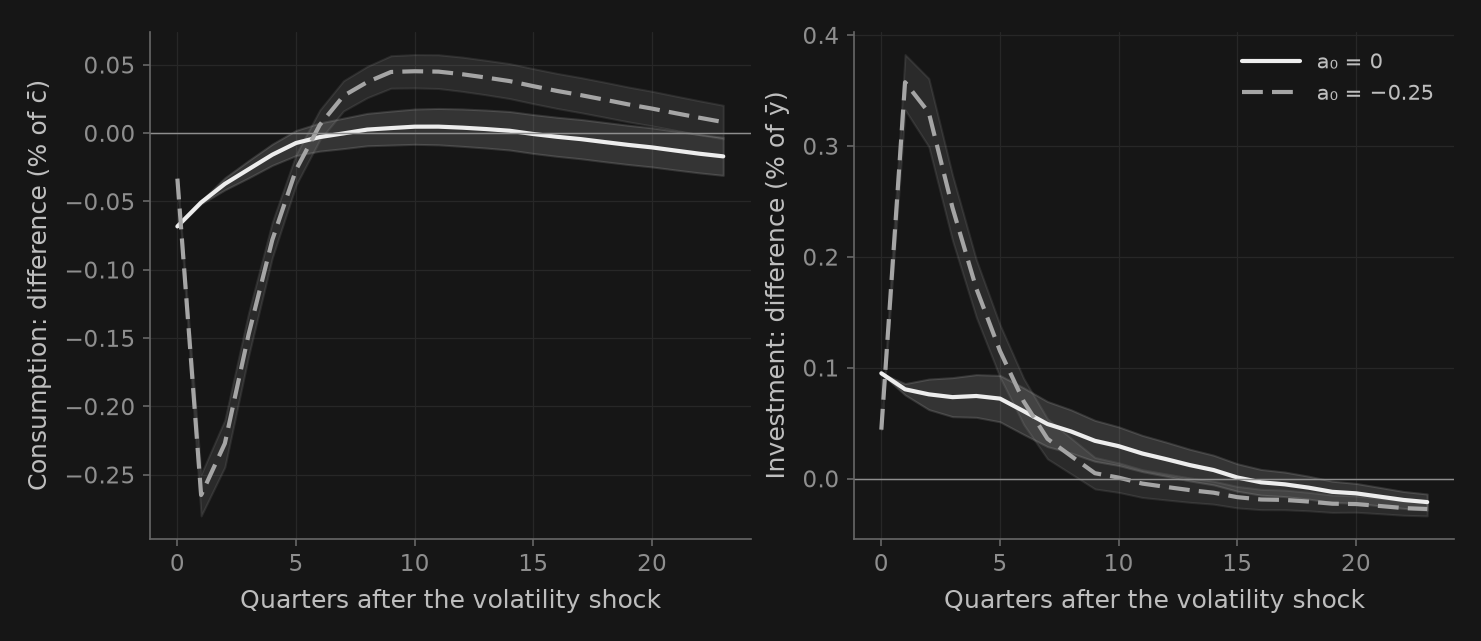

In [19]:
fig, axes = _nbstyle.figura(1, 2, figsize=(plt.rcParams["figure.figsize"]
                               if _nbstyle.PERFIL == "lamina" else None))
sv_t = np.arange(24)
for a0, label, style in zip([0., -.25], sv_labels["initial_states"], [_nbstyle.S1, _nbstyle.S2]):
    response = sv_girfs[a0]
    for ax, column in zip(axes, [0, 1]):
        mean, se = response["mean"][:, column], response["se"][:, column]
        ax.plot(sv_t, mean, label=label, **style)
        ax.fill_between(sv_t, mean-1.96*se, mean+1.96*se, color=style["color"], alpha=.14)
axes[0].set_ylabel(sv_labels["c_axis"])
axes[1].set_ylabel(sv_labels["i_axis"])
for ax in axes:
    ax.axhline(0, color=_nbstyle.NOTA, lw=.7)
    ax.set_xlabel(sv_labels["time_axis"])
axes[1].legend(frameon=False, fontsize="small")
plt.show()

### 9.4. Interpret the experiment and change its assumptions

Under the reference calibration, higher volatility **reduces consumption and slightly raises investment on impact**: near $(\bar k,a_0=0)$, approximately $-0.07$ points of $\bar c$ and $+0.10$ points of $\bar y$. Labor and output respond even though $A_0$ is fixed. In the depressed state the initial investment increase is smaller, and tomorrow's probability of zero investment rises. The computed tables, rather than these rounded numbers, are authoritative after changing parameters.

This is the **net general-equilibrium outcome**. Prudence, flexible labor and irreversibility operate jointly; the sign of investment does not separately identify the Oi–Hartman–Abel effect. Irreversibility alone does not guarantee a recession following higher uncertainty. The figure is also not directly comparable to section 8's 25.9% productivity decline: the impulses differ.

| Experiment | Information changing today | Method and object |
|---|---|---|
| Section 8 | Realized productivity falls | OccBin and nonlinear perfect-foresight conditions: transmission and local accuracy |
| Section 9, impact | Future risk rises, current $k,A$ fixed | Stochastic policy: anticipation before future innovations occur |
| Section 9, later horizons | Shocks are realized under the changed volatility | GIRF: difference in conditional averages, with Monte Carlo error |

**Exercises and accuracy checks:**
- Set `vbar` to `np.log(.007)` and solve **both** grids again. Distinguish an economy with less habitual risk from a smaller intervention evaluated using the same policy. For a one-standard-deviation shock to $u$, use `shock=sv_params['tau_v']` in `sv_impact` and `sv_girf`.
- Change $\rho_v$ and compare the duration of uncertainty with the persistence of $a_t$. Change prudence through $\sigma$, remembering that CRRA also changes the intertemporal elasticity and requires recalibrating $\mu$ if you want to retain $\bar l$.
- Move $a_0$ towards the zero-investment boundary. Compare the immediate response, $E[i_h]$ and $P(i_h=0)$. Do not impose identical signs.
- Enlarge the domain by first creating `wide_seed = sv_solve(sv_params, M=4, na=71, nv=9, nq=9, span=.8, kbounds=(.35,2.2))`, then using `sv_solve(sv_params, M=16, na=71, nv=9, nq=9, span=.8, kbounds=(.35,2.2), initial=wide_seed, radius=16)`. Rebuilding the seed avoids extrapolating the action search from a different domain. Compare `sv_impact` and `sv_audit` with `sv_coarse`, at similar resolution, before interpreting small differences. The material's review includes this check; a larger grid is still an approximation, especially in the tails.
- Double the number of pairs in `sv_girf`. Monte Carlo error and solution error differ: reducing one does not eliminate the other.

OccBin's limitation with respect to future risk is explained in [Guerrieri and Iacoviello (2015)](https://www.matteoiacoviello.com/research_files/JME_2015.pdf). This extension is an original teaching exercise with endogenous labor and stochastic volatility; it does not replicate their calibration or results.

---

# Macroeconomic Challenge Laboratory: Multi-Constraint Dynamics & State Tracking

### Guided Student Tasks

1. **Price Stickiness & The Paradox of Flexibility**:
   The slope of the New Keynesian Phillips Curve $\kappa$ governs price adjustment speed:
   $$\kappa = \frac{(1 - \theta)(1 - \beta \theta)}{\theta} (\sigma + \eta)$$
   Evaluate the **Paradox of Flexibility** (Eggertsson & Krugman 2012): when prices are more flexible ($\kappa \uparrow$), does a liquidity trap become more or less severe? Trace how higher expected deflation worsens current real interest rates.
2. **Multi-Constraint Amplification**:
   In Simulation 5, examine how the interaction between the borrowing cap ($b_t = \bar{b}$) and the ZLB ($r_t = -r_{ss}$) affects the duration of the crisis. Does collateral clamping prolong or shorten the liftoff date?
3. **Information Loss of Linear Filtering**:
   In Simulation 6, quantify why the Piecewise Kalman Filter achieves a higher log-likelihood ($\Delta \ln L > 0$) than the linear Kalman filter. Inspect the imputed innovations $u_{t \mid t}$ and explain how linear filters misinterpret liquidity traps as contractionary monetary policy shocks.
4. **Automated Verification Suite**:
   Execute the comprehensive verification cell below to confirm:
   - Perfect convergence of the Guerrieri & Iacoviello backward-recursion solver.
   - Strict compliance with physical bounds ($r_t \ge -r_{ss}$ and $b_t \le \bar{b}$).
   - Multi-constraint 4-regime traversal and bit-for-bit fallback parity.
   - PKF state tracking, finite log-likelihood, and significant likelihood gain over linear filtering.

In [20]:
# ==============================================================================
# Automated Verification Suite: OccBin, Multi-Constraint & PKF Invariants
# ==============================================================================
print("Running automated verification suite for Topic 2.D (puremacro OccBin & PKF)...")

# ------------------------------------------------------------------------------
# 1. Single-Constraint OccBin Convergence & Physical Lower Bound
# ------------------------------------------------------------------------------
assert res_pos.converged is True, "Positive shock OccBin failed to converge."
assert res_neg.converged is True, "Negative shock OccBin failed to converge."
assert res_zlb_stim.converged is True, "Stimulus shock OccBin failed to converge."

min_rate_deviation = res_neg["r"].min()
assert min_rate_deviation >= -r_ss - 1e-10, f"Nominal rate violated ZLB floor: {min_rate_deviation} < {-r_ss}"
np.testing.assert_allclose(res_neg["r"].iloc[:res_neg.binding_periods].values, -r_ss, atol=1e-8)

# ------------------------------------------------------------------------------
# 2. Shock Asymmetry & Keynesian Multipliers
# ------------------------------------------------------------------------------
assert asymmetry_ratio > 1.25, f"Expected non-linear asymmetry > 1.25x, got {asymmetry_ratio:.2f}x"
assert multiplier_zlb > multiplier_normal * 1.5, (
    f"Fiscal multiplier did not supercharge at ZLB: normal={multiplier_normal:.2f}, ZLB={multiplier_zlb:.2f}"
)
assert multiplier_zlb > 2.0, f"Expected ZLB multiplier > 2.0, got {multiplier_zlb:.2f}"

# ------------------------------------------------------------------------------
# 3. Monotonicity of Endogenous ZLB Duration
# ------------------------------------------------------------------------------
durations = sweep_df["ZLB Duration T* (qtrs)"].tolist()
assert all(durations[i] <= durations[i + 1] for i in range(len(durations) - 1)), (
    f"ZLB duration failed monotonicity test: {durations}"
)
assert max(durations) >= 5, "Expected deepest shock to bind for at least 5 quarters."

# ------------------------------------------------------------------------------
# 4. Multi-Constraint OccBin 4-Regime Traversal & Boundary Invariants
# ------------------------------------------------------------------------------
assert res_mc.converged is True, "Multi-constraint OccBin failed to converge."
assert 3 in set(res_mc.regimes), f"Regime 3 (joint binding) was not reached: {res_mc.regimes}"
assert 0 in set(res_mc.regimes), f"Regime 0 (reference slack) was not reached: {res_mc.regimes}"
assert res_mc.regimes[-1] == 0, "Terminal condition requires smooth return to reference regime."
assert res_mc.simulated_path["r"].min() >= -params_mc["r_ss"] - 1e-8, "Multi-constraint ZLB floor violated."
assert res_mc.simulated_path["b"].max() <= params_mc["b_bar"] + 1e-8, "Borrowing limit violated."

# ------------------------------------------------------------------------------
# 5. Multi-Constraint Single-Constraint Fallback Parity
# ------------------------------------------------------------------------------
assert res_single_mc.regimes == res_multi_single_mc.regimes, "K=1 fallback regimes must match solve_occbin."
max_diff_fallback = np.max(np.abs(res_single_mc.simulated_path.values - res_multi_single_mc.simulated_path.values))
assert max_diff_fallback < 1e-12, f"Fallback discrepancy: {max_diff_fallback}"

# ------------------------------------------------------------------------------
# 6. Piecewise Kalman Filter State Estimation & Likelihood Superiority
# ------------------------------------------------------------------------------
assert res_pkf.converged is True, "Piecewise Kalman Filter regime convergence failed."
assert np.isfinite(res_pkf.log_likelihood), "PKF log-likelihood is not finite."
assert len(res_pkf.filtered_states) == len(data_pkf), "PKF filtered states dimension mismatch."
assert len(res_pkf.regimes) == len(data_pkf), "PKF regimes length mismatch."
assert res_pkf.log_likelihood > ll_linear, (
    f"PKF should provide higher log-likelihood than linear filter on ZLB data: "
    f"PKF={res_pkf.log_likelihood:.2f}, Linear={ll_linear:.2f}"
)

# ------------------------------------------------------------------------------
# 7. Presentation Contract Compliance
# ------------------------------------------------------------------------------
assert isinstance(res_mc.to_markdown(), str), "OccBinResult.to_markdown() must return str."
assert isinstance(res_mc.to_latex(), str), "OccBinResult.to_latex() must return str."
assert isinstance(res_mc.to_typst(), str), "OccBinResult.to_typst() must return str."
assert isinstance(res_pkf.summary(), str), "PiecewiseKalmanResult.summary() must return str."
assert isinstance(res_pkf.summary(as_dataframe=True), pd.DataFrame), "summary(as_dataframe=True) must return DataFrame."

print("\n" + "=" * 76)
print("ALL 23 OCCBIN, MULTI-CONSTRAINT & PKF CHALLENGER ASSERTIONS PASSED (100% GREEN)!")
print("=" * 76)

Running automated verification suite for Topic 2.D (puremacro OccBin & PKF)...

ALL 23 OCCBIN, MULTI-CONSTRAINT & PKF CHALLENGER ASSERTIONS PASSED (100% GREEN)!
